# Иерархическая кластеризация клиентов банка

Практическая работа по дисциплине «Основы интеллектуального анализа данных».

**Цель:** реализовать агломеративную кластеризацию с Single linkage, Complete linkage,
Group average (UPGMA) и Ward, построить дендрограммы и сравнить результат с
предыдущей работой по разделительной кластеризации.

Данные, исходники и сохраненные результаты прошлой работы встроены в этот файл.
В Google Colab выберите **Среда выполнения → Выполнить все**. Достаточно CPU.
Ноутбук создает каталог `hierarchical_project` и ZIP с результатами.

**Каталог репозитория:** ______________________________

При исходных параметрах эксперименты выполняются в шести стандартизованных
признаках для 850 клиентов. PCA используется только для рисунков. Все таблицы
и изображения ниже получены выполнением кода.


## 1 Параметры программы

`METHOD` выбирает меру связи, `K` задает число групп для демонстрации. `DATA_PATH=None`
использует вложенный `customers.csv`. Для своего файла загрузите CSV в Colab,
укажите путь и `FEATURE_COLUMNS`. Сравнение с архивом прошлой работы автоматически
включается только при точном совпадении данных и подготовки.


In [1]:
METHOD = "ward"  # "single", "complete", "average", "ward"
K = 4
DATA_PATH = None  # например, "/content/my_data.csv"
FEATURE_COLUMNS = None  # например, ["x", "y"]
KS = list(range(3, 10))
RUN_NOISE_EXPERIMENT = True  # 10% измененных строк, три зерна
RECOMPUTE_PARTITION_BASELINES = False  # повторить прежние k-Means/PAM, медленнее
DOWNLOAD_RESULTS = False  # True скачает ZIP в Google Colab


In [2]:
from pathlib import Path
import os, io, json, base64, zlib, hashlib, zipfile, sys
os.environ.setdefault("MPLCONFIGDIR", "/tmp/hierarchical_mpl")
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
PROJECT = Path("hierarchical_project")
PROJECT.mkdir(exist_ok=True)


In [3]:
# Точные байты исходного набора и архив предыдущей работы без сетевой загрузки.
EMBEDDED = {'data/custmers.txt': 'eNp9ks1qwlAQhfeBvMNddGGhVbvtrlQX0kXBXZdR0x9QUzRSuota+4OCXfRBYjQa/+IrzH2jnploEcEuApfcme+cM3Pph3xa01r3KVQUK1rQkiIK8adDvu4pGknBgvy0adC37mgP9yPdxal/aRpF50WdK9pQrD09pAkqYwqAmyu0xbSiUHtKt6Uxxm1kGtetpuvU7EahglbdRV3EArTUA3GC1gikxESk35JrnKFx4NA0rh5sNhAAPoOEz1IqxYZQBxpnWMJE59Q08pVW2XKfnDp3xEiBepqxYQkJqkrpd7CXkPqAdJtbt/OZK8k2AefOthrNfO256rzakgHhkGMipBiVbALI6TEjhXoZA2AX6NE9xqrUzYmqKBpvNa6tRiVnl1wumoE1Ec40sYMmnuhABq9kOh4UYR8GQv2Fjx0Eu2oKQbx1H+3GDrnhdXBG3vsRPkX/8nL2vdWqujIB4UUArYEKZJdtPfx7PSLW4edwxpH9DH6GsqcjeHWRzmay6azIlNxkXkXenawOxezxUxokQmJ/TD6msTdVyK8OVfit78X4BVPv1wY=', 'data/customers.csv': 'eNp1XckO7EZyvAvQnxCN2pej4ZnDnAz45qPskRfA9hgaDQz/vTMisopskk+HB73XWd1kLblERmb941/+9/j7v/3197/816+//enPx9/926/HH//8t3/55ff/+Mt/H//06y+//fWP//U///mX//v1z8ef/vtfTOr4+19++/Mffv3n349/+P3ff/2N//eHX//1l7/95+8mg79K7h/xFT//FI54lHikox1xHuETUzniJ/Rs/x+O9sk//4RPSze5ZDIhHOVTRzrGJ8VBoZg+4+ef0pGPnE00hqN2GxmjCe//4lE/I6TLv4SKHzpS+Myff8pHOdLED+kx2gjz+p/9U43tfKZyVD1Ttseq+ZifHIY90wx6pv5JP/9U7aUKXjDlY0T79zmHfTJsjD0lfrYd/ciDP1vx7aUk/Fnz14/rd+On/fxTP8ZR8Kr2HMX+OfXxJWpf95ml+oPagHFMzps9L6er9nokm7pqj1A/9eefJibMXiXjKWPE0GYvhK/p/JryCbYG9vu2UMXE7DXxRWlUm9IwMmfRptuEoq3FkW0m7UftxcMndz5ka4ce3z6O9kM2yfbiep6Et2tlrbc9kUnEchQ8dDsyXrzYY+XPaHjozu+xb7D3GHhqW0H8RsaDtNKuszH4bPNTbIS9f9Mvx4MrGQc2QBr9MAlbLfvH2LEJKIF3jxmrkaaeLfHZ+NgF20X70bbFDF/7zL4za+ZsjfGsA1uq8JfH0WyYbUR7sU+3XQwZ27wmYG+Rm56NP1ttRLJFKGuvmECK2qT2IlinOvBnadXXyV4CEglflLmsePJpP1k+LU09U8ZymoytNuevYfFtJ9hK2SPl+Jy/OHm+uG62tSJep9tM2Za3efhE//2BaTYRezR7/4LfjwkbKdivRTuu1Wel4wCZlE2fPWC0vWL7w76thPtOLs0WZ/DXTaJr+Qqmwb6Ih7L4Jk2YaUgM/DgfEefqUyfm287TgTe3BTSBpM+wEyu/I/A9/eQmvsbExls7Gfskxv6tEOzp0l5m2/yQj9j1GcsMPWX7llssxHpuIJOx5bUjnHBWauXT2YN8euzfyolfXbFaNiDzeNq+wFB85W3T2U6zV8ZqZaqzjIfnw/CY2J5sOB/VJgfPiy+19dZneBC+46jQvS1GV2HdpCo3E36ay2q/kG4/nUxbz0PLD9mO780Sxx6NPMAv57JyBBUg1yxw4mwEdEbPvvkS38dEJnZ21CmC4qPySL718U3UOfZnxhmKPJzF5rHbDk1fS2dqxraUCcPw0ABB4dh38vTG2l1t2PubhE14wUHB0Y/Yz7m36wxkbgA+NB/X5hZDeLw4azhYYY7vCShmDFyvZD5Npna1o2g7Lna83TA9Oz+1aitUzEPhCSxYtIwDgTfEGczFN2+kcarQngWrMI+BNU294X3siXAMbLcWHntO6Hr5RMOQ6jqktllNBK8ezlOX0re9oQo3bXbwcJlwmdpTWXY0tUjTOXyd8NPzqEF6zFQEP+/zdrhs0e25bZ1gRe3dozsA6eB2wi9CN06fGftpE6nJNWg8aAxgdkz3V0llHj+TqW6A+IQ2X9XeEHZU3gC3kolUWmQqkgZrMfAAnwzTnTHH+LxSldiKdRy72OGefHotN3NADWqLZ/L2lZmWwxW4uTn2WL2vrW5KzERsA2ZtdZq2LKNc5K8U7BaTsMdOXfYPz9d5FEYebkdtF5pEnXJApryFTrWV87ee3b6CSbeAxdEc8rUzfnv4VuVvNy5anrKSjRoTrkDvy8DYuTGJlvSutvZQpJ+IOcpt6TWbZpMwraQ1M8sIM5QKd6GvWYzYACZjTw9zCDGzU4UHv37yLOsn8W3lMEsEA4TNyolL+Nx0z/W4Bo3RU1YsbsZMD1pom8ab32f/NL8UXnJjZxNsY+2h9ZLmyVE4Y5VKqqfrZCJtyAcrNGKf0vElucl1sj1jG9NEGu1SlCeGqU93RVt9x8fCp5/YeGsvF19+Klt9MZ0yE+mR1uwYOm2V9qwuc2dLagL2SFCI2MxccboW1ecXu9cEbLfa99BwTRjXaS9rRzrF0+U1kU4XAJoPjqq9JnydWG6bzr1PE+5VTtfEqbV9PsvdtI157j6T7jRI26OdNLJ5+Vy0FyZi25HexTjoDjep1NDvbn3QebaPTQXAIuLYRfqudA8fhhZvip8YWHGGLiYeoW3p+NnamP++ngVTYjo4QCFz+1KbF/h7H3ydTJd9PqS0MLcNi5hb/X5S0/99LH/DJsIGmP/IdQ3Y+Gb3eaxWWEPzhTgpn04JFIudCpucT8jt6W4oYsiwGdyJNH6Y//BQz1CEE/vLZG0BCtV5hKbGtknf8maCQ784NDZgNB0J/BMmezD8sc0st8D+OmifbAdiO9muno+TWevtZPqM28gxZGGSfP0ig1Dk/di+s8/HlIUeVAD2/XSsNHuDXzOPCfPMZ6BPPrCA5u7oeNHjMQlzMW3d+fo8O40/Nmfy3YUgy7Z30u6q2uYx5PDY536SeCZN3rQudZNvSDPi8665U3G7xV8xe19WBEMNWKFT7KzH73nyx7fFNvkpF8UCMvpUMSmomP4oNhEmMeUvmBBVUKJmiIidGJvYx3DYO08lv0ZbPNqfir/sY9MZ2lX0rMN9C0oz5/6l9ZYfzMcwd2hiIZKcWnj3hdtAL0T9gI1hvndSjKzQMI7HvHWfaipSOushytHpch4Q1ZhGuzvlnGvuUAyINpf2SgWhROSxavFr69vEmeFW8MEfgs/jJs+erQVuOTgzy4H074ZTWRQ0yt+z048YqbprypAcMRanmxaPyzrq/ZCM6I50ZpCLdwhN7lSkJ+aei0l2N42MZyCFU1uiJoW7+bY43LS1+U6ZGGTfa4EUTuwx5KE+YhXb3m3cnUiuH18dwdM8oRxuNLxbhefF97bXikEwiE38wIfwkezPGU+NHolZRPcvCvy+CJ/6Hq3HnH3msULAMCLdMz/1tjRw4IsfZ8cf8EQxa8dERh2JCxm53IFrBLgAG8PG00iHQ4Y5PACDWuOy2HhBoBtAPBJnXs5Ai3y/jOMEwADvC6hgMkSF6IfRfhvpVOWQsMB1efAKnFKb91isuSWE+4pRiHSG26NG0/XBQcupfo80PUnYx74j+smM9OkqDqVZLIfMIvUpZCJgjqz3am+mAvulP02uJgbB2gUDoZVunPrSlsOIWYdBBsQxzrBVuOK840Py5bBbcH4SIcSiCTUdNhvDiHKGGRDBV3He7e3qq8uCQS8vIR2AB0m+utHj+QoHOfnS0axCBCqFMNg86DEOKr1u/39UzQfi3K6JzwehkEKcp7Q8n04+/TgMiPgiTQ61fc5PDSmLvM41YrrkSKIcnk8guBOza2htSxgf+Ih97XdYCZ6vb0fKZyRyRrA9gYtUh784iu50cCiTDj5kAMktOcbpEYGzRWdpbWACiAB3aDwdKzPN6aBaevp/vmmwLWEIk0CTzACCoVV48QGLxkD1b/+Vfkqgh7/sFtEYiCDygbssnNkUEcONXOrr82BxobcyA3BOOJcjcp+Pu5aXfYR0BLIllIzRbaQfPwOQU/9aW8m88MiEOQqMgS34LOOJOk+tkH0XwoOgA1UdpjHnv7ZntNu4Wgg8C9UvoTZ4yqYQEGwD/rwKQj2nhW/xVBfa9Nzjc3YGHwinBhBLowNHrLkAHCHS4ZOI/YgQALhKkD3CovaW6J6NZ1Qn9AYD6M+X7Y93M6MdMLEranMBcEYRkkM7CocmVF1TvAM9xcEZoQAYEIs7S/AnhwziN6RkByvcUCZsbigqmG4ALcB4M2Ics4qYPvM7y9XSw2uAW8642R15xofVLbYMXkHYEBSyNSllOrjXbQ5IoK4ApQjYi/OJBPWWTzQWI2JN0mD0I4RYT1jAA7AXYXl7OKQbMIVFnnjO8enpR3d8MAOw5KYxlX9xNLhhY8XWvv1JBxogHWtdgC5ggg8djc9My1xiyrDrajsVUceGQsICLjRzD5RqiqSmECnYeEShmLRZw9O++GzY51UoA08oHSEECfZxe0FkqkYhavNAReOgrGEFmp+hzp1oMrERgQbmV+n1I+VVQ1nOMb4ODmeLKw3iIAn9fXNVBc/h89hWDiHLtRmBOYTR10ZmvgQWMHvMXA5ar9L6w5LEoXlQpgOoRyse2BDXw/YvV9SHIQWE4ITz1dvBdWpEqcdVa+OfGm1GQSTH1dQbjf4C+ygLhbkDchOZ/6CLWRgWxUsABonYHP60D4T29/IwY7E9T0I4/CVs/ZrbzUiwBngedW5emQucwgbQN0DZIxSj1Zu9Eq2rrofxSB0LHrf3MQALQHl1C2jq8qJxRDrAuaRZ7lpouLbIssyl6ihn39Pz2jdp0NnmVId22bwd8HcR4OiPl2zr2paoHl3IuJhMxGNzcbOmLOUv3ebznHyTc5StYacvBaeBEFn/ToE2SH6bJ4/FBqcZAQwAHy5VFcgyFFe1C0gMmdgdjOvaUylAYMYXx0BKHsiwOSN0OpUNsdPCbG7PC7eFjoHDMgJQaEZWBK0y01jdXSkFmwP+sK8htWP5YHdazFLveYUzJADsPZJHRVkGz/7xNrFpe/LSVAiNxs63UlFW2oHw8rbKtSOfO1y3wlHBawNHiDSOvd6ddZhCjkN4UaHl+YhYndkeiM0cUkfJfwwQXpMVZ8KiPVfZ9GD1U+lTYYs3+k6CENemiz7jizPVNQZp25Ua9EGNO7EKiji0j0wm2sJRLgXZLHseZFjm4dgiBCyk5crZrJKpIJMqfImbZkJLxu13cBd8Q6CDaHG7OXJJNn5iCznrAZEggZgYvzWrbU+H+5PMNBAsYEZdKTCCUSF9h+zydOyoHYryJ9IgRQBWkDdo8dyLjpMBllYD7GJLQ3fQHk/ngLBJKfPisOOQzrbzgfKPGCTXW8S0cuWIuCa3atrxA5XhTmwwW27zYhNY3SbCnJgEkfVlQbDqmGMsns9HQthiTg9sLvyrsgwofxj7PGj/BneDuIXyLWToZ+CCAcgZ6rAoPWhqFcjsTvrSVEIoCSvaLm6jCsxmfA7aZnye7NATuYqKJeYN8cMEL6XDrCEHhCJfZGyYkMhfOVMQEEkWA5QNy7ynRdL4/jfbJUqsA2Yyg1Cjx6zwtKfSYld0CTIp9A3eaBq5qXpfkVyEHGzSEEAPz5NBcIMRt63RHsGWP4Q9efCEls3SXFirWQt3TLLkbCkj7QjcPQ/kyL6JnnfG2kEixu2H0HxGBinRVQLjcMikuFJZtNCBkIAgO9kICMBPpN6YCkwz/+yO2dP80JWMhPUIxvCzSvqECDlcK8BFkcmTrd8aXJHP6C/ghc4NBqTYhLtlx5kAZZnL39c2x36BTOwyPl2ZhgfeYpIpPU2tM0fAkYk0oZgRm4iOlCcg/tq/B+GUgekBacBDnk6Vc5OYxatUqpxBpPeDtLq9TJNrSjObX8JvDQIlJsWlLRQ5Avn/xLxTqph3smKS50E6gbMEm/a9/6Hk54k2YURKjiKQD7JsxlK7lVOKuBVBlvIE3G5PL/hKacPuw4DkjpIjWT09cMEQy4lQMUGf2vbpsiftEd4vGgRoQrCmtvfrZqIgVdrJmGvLReTkwQEaK10gzU+XSWlTz3FSJE0ZFSEdRDcqnncZH+xAOAo5KNoDOIPcXwCY8mm9XagcEErZE8jzoHsr8laN/XQKIZLyOndFJBZMvH1f2lAsBXHGxYZgBopKhKHbWASdph9GYpULhTkXYEytBGsY6Yfr8yrQ26bBvKFmQevDJTGd9sSypGoRDgHzmCdXJWRFCW45MPmQwDMWPxPc7lSrIbbN+IJVFqCTdqIskXEzyyXFS5k8BV1NaGlTmOMWClvYXcoinPBBgQ0EwS5ZGZlEaCTlcrJqKFJcTxZFCGnGm+mwgMm3dyQDBSOg1HXmKxYb0PTDP6ttJclgPYBiANSREuOOHOPhQ1oAKdyZsqAFeHBFJS/eT+7jDbLDCmMACDJZ70OArz5+JEB/df0K7FM7PeImr2Ayt33LYyhfBnH4gvwNcFwIycZ4s63w+1felTMNgts4gSESHSZzieUFVnDFCXywTGGLsE9U1oVGsWKioP8AAwHjGYu2iDwbA++ys+Z4AuJAUQSe4Rov8mi6HMMKilTyTrh3GORRJTycdz8XHJRIlBVvZHmaSt1/p0LTmezHAKQaidtkwc4I1PP2M5P8CeDnyDi48RsMhZSuC/mymUHZqU2YAiFJU+GzU/OXC7BHmQ3xBG3fjgCYKeqwMsSQSXVIpSzG04ORi+xU97QyHwL5sbkH8fmI65rLcDtX7i5ButHA+Z4FxSReiDmMXijSohwkJ5GUQBS4L++ZYtgCaVlws8SNhKr6KXBG3cxTIO+cDhbhA+8c5OtLug4y9IYmkYHKfCtxnFkcKpUYHrtuh0/xmi3XtBhoK2kcTyA+rSGCxzsUJbEz0c01h3w8RI2e2Iq07EjvL6hQUR8EUhvCFuFTIC8VEJXZTMcXbCjrUeHcLDfTIRHu0/G2T6UjAPH04Aeefj400aQynRfXFHydHjfNBL8rhmr5zjHkq/fSEVwkRfHDIaSx6AinwYRIzw5eRp+6nu560KzZoaQOpFNfuaxBDUd3FNSUdqPrdD0/MKAq1svKHc10I6snUijdOcUpAcOnN6mV5NTqF/Q4pXZyGTigd9m+JPMPN992Z90eLSwNZPqQb5e5b0yfw4nNadtIfh/inim7vEIgQiaplBNho8gIgiSWuUtMgO6ogCxiaFMFfUeVRuVBjuR0863xsf2NdDrs08odVus3FzVXHKuv+XOqIgankeWLwFtJDIR4uE6mCNYREM8om09DS85cdHL/UWkxygynjwK4DkxJhnyHFfLO/WBvD2Cw7WvPlnhXVJEpm0NBBiCd0X0nVjCxAETTK2nxGrWA4jNcfXZPReWn69zDS66m6RuQyJwOponFAeMcLw535KkG22cGEVBs8oDEewprjmfA6XsG9J+F4hTxdupb/u2k3+MwI7YpyksJG2K6DA6FDirwh5mVTfGAIfS+dpBjLJBIs7j/Sw/KrFSHClvHRP4MGT/OAmnuxr0grqmOix3EgNlcfYo6whzfB8DxZcfgNM+uL1/5ArJV29jkRRxCyMyxeXxEJ8ltz6FezCVFpsgVUc8aFcDX9oiX3HfBGREwwzoaIq/gzSLBd/I/QVXHdg7RufXxILf2wTRJdO02lJRJ+0luI5IM08D0mHZtb1kZDkKyTwUzYCEyXS5aVbkwBCGSQ9FCS39TQGR8HbAGMeQnPRZMWozOxRhtXvKklAlNUF076KoDDDU3ciyfBAUGEAkLC6dDaO8cEcisYok49Bawn2K/yW0y3eqpsUwllCEEP3Dq9GfZ2YcdrNy/rpMTBtmA6IetCUVNpIHmcfFXKBKjOKVDBVA5361JRtL12zZul5mjY1r7mAvREYGS7nHm0ikTsyffnColvl86fBUA30QvAsuKtWIRxe6S1IRI1nG8gBlP4LmX+QP+B0fHk/3Ig8/srKk5VxH4HD5jbiehrqcHyQR5LLk6FI5DWEVw3hVUnoUoGwnBmlNm1b8kOQmDWLQ9ww2SpStM6eRr6dpq0FzPtriSEINIisJPI4+p/TZeEyFEW741NkdCBUxy5qzrCgYZY77gW/QKIZ9TVklDBckxEz9tKCp6ZCSkuyAPF2DVDBEuURZ8MNeJHQgmD2EVMSZo9niYYhivdBW+AMg7TuRHDRFx0FYeZO26DBXnB2VdXbFt8NK3yMB5jMXH5BOBzjMWxYlypf4IUvIlAv8g+RnFTDLwKfERAtfe396JPwvGXTi3NXPjrCyp44WOybCEA3L0iejIOkM5kBkeLzR5ymQ3iohhWEUT5y2dEcG+3wodE826p/xFDOn9QXBscacgoRLA+8ln+WBk1qmRx98urGzIZCE94HuJO5W/3RqMmjGfPjYG5NyUeJjyhQbj0U1pmfpyUNS7DITrpcApSZdaTkggmS9/bIDMb/OdCQK1diGkQCjn6Q5VcEtC5yWk2/J4CRDF7XTXrEyx2EY5PxKxOZ5sAwyA76QaKqUonzDpmWVRaRYGlLRzZrW986xquu43DCh5U2xUaCmUCKAwwTgJFHHL0/I+gLvY3n3NlPKb4TO5grb5ZxKd3K5Imkw4jxopPk3+gvNTpv+5yjc4KTjqfVEwqCNQLHli+6rGgAzKsJKAUpXZkgxW46v7ilUC3COOjtPqFnvB3m8+fcygB8JOCJo7Z5N3li+1vLwPfDdEVuEUmXONUAz+t3tEu/ATyOW6IQHam8z9WvodtdphBwbkugLOLoZRmHdaO8zUys5gL3NEWci3uPA02amcfjQlqhPrFpEgEEdbalXuCUg9Vdt7FZBUOQDLX+O3IXzpnq/MhMTNdMBKIpwMz4pXbRAgQKgO06zkVVKUATI+J0WEFA6ojsU6bSVrsgcrD1lUiWyI4zmOEZPl85m1XmpkIZObKhAZAQ4GokxVpF1egC2BgqyW5Bp68VNkoVR0mlBiwpIyzQkBnnZ4s3RzlKeh0FSyYItWldkOrgjL6Dzabnoem6VWxVEr8sRTyvcz2+M8Oe+QR63QQgloVTvZ0Sto9CcA28d56SZFWN082/mNPGb84NOd8J+Ca0UKXVVkzRqRfg9qs7NpPWuJIaAb1+VDJlY0Kob0g8eXR7ZkVXN30Ys6XbLFDVe9KmS6Mr0ruCo3gr2o38NnFisI9IhIz+END+LKgd7n92JIwQTq2dG3DDJxJFKBbXR5cKBHXUT5o+nMqcIi5ofvuTxw4Efd2czuQQ35Z3cuntN1cEYwoDfNkKiH1GDJPW6aUb4sop0uZ0gV2ajwf6QebLetDd5BrByuk4Z0ErPXn+lT0vXYwNmdsu7umAW7j4R4L6tUGc4zBgynSkbHWVQsUsnLZ6EyXOWo7K1TQksXO//FCug1wQYaSRth+umlp1VnPWuIIIL4KankSwqulJcSmtJfdTY0ygDVsgiUcqdYSe+edwEzfwsVYFVVa9jqhQQlctIdgqLCw6kwMXDFRQ6tizkff5S20FbDgLEyJBOVdIE5ykpCt+T4HCgPHwoRvQS5zHuF0I/w3KFXBgI8ZS6zyOVNyqqNMy9EEQBETiqtm0nRNqUFYhABJDROjnUqKkDcDRbwgpCZyfHzCEqAqZ6CYGnBNyRwUGautIgnyrizVmosSgwiZeV+xaWejwxfnfFxTHPQcwPnrdpjVWaphPQIKXbSRl1RoEhnU1gZk7zI0VSJdAvWPIyG9PQjy3AxetRVVS8CFwCkuMm6TMUDrLKpddztQwnp4jigfGxOzZTqE5nXiEhHvsWN2D5g/wR3lXy7Nx6c1m8pP3nAEC4hCnWmnTSdRPNVnBoaCYpChokoB1loyDL3Vj01PCRK8CohF2r8zrpdVv4ogJWyiyYYGxJfe1Qjn+1u6AUs1Ejr+onqylHGiyFQ6T04QKr+YqKY8w7uhsVrj42Tgoagh01X9V/x2jgyQqLrxi4xuFe+ppGZOKVi7LiPdRopB6h+slWGbWTuuUF63Jw3+yUWBoSL5zWPLoej5ydTgvL4AcjG6J6jZ4ZaFjh3gRQgU2Ly8oSkUrzHfNvO+y4e7Ce8h9EFvql3MqCK7CHfk7xpuS+aAJZCOGPLoahJ7C2+Gkx1a4CTEXlsydKr1JaPotzseCHLAyFfohcQxaKiDQYbn5TiJT1Dodg3NN5WTxJTnyjwjOqWAQ8/ruy0QtDBqR8pv1SXVj23rTbghKTFIDMB82ZugJ/txKhdQu4zlUXGKg/iIji9orRBGjnQ1WKAhVgMiTcTmjAQZEq6ALzqtYLC9ewAlii2ECrp5JGIe0SWSEF/E8ELkEAKmFjLIgVVsRK2dYMAWgAUr3btSnjYt9jK2G6AG4SJh0hqfmaGlrXePFmkTkp6ojZdT4PwtW8yw3RuJ+rW4xnCUiSRURDF8sbZZAHteKMcM/eOAUWoUlaXqkj4FpDQbk6DNTaZkoP8du+elcjHexrqswcImEKLBCS2EGIVRGXOUSGDEyIlp1XInxc7BQVfYMloo1PAU9XJkds4H2FoKs1PBx8A7nBZdcLC2RjPz7cWAeyFA/mSneMM+l6ElWnKice17SmITHcTbaGsVh9EHs8kAgRK7qsmRVR5Wt94K94bJ+MUA0oeuyycLigN2mj5LNiBSLG5ratbE8uQ2AtnlehE2TtWggVPdseDNIR5r12M3g7Cy2Q4oESPwIiqI4MVd5eF9bCQ8VY4pHzI8Na72lq15owNOKB4ifSqR2IFTrpUaxa2yykKxeCdlMnar8xN+YW9L0gEUw4wqVRPjXR1X2KRJZTNPuKQKG0BOSytAjRfP0tfTLXiAezQ3YBEr4tnzjG3VWzCRwXNy0vfK8/gB9onpXJJhUICnBYxvrtnDgkNj3QidBSpXkKLqU/qycMTX05AADKlLjg+HUwTzW/aFhJXaG6yCPmYfAypSV+vXLmbjFavtGPIoMlF2mxpEOl/EL+u01OB33tC09Fc8vK9AsnJRRApovIwyo3qvgM30ZRmm8+avagnB7u5aTXCwmrGg5lQx0ugoE5PgJFqX2gzaK5kzCFp7ViZv4etTh3bp6QTxCoYoIJqdoDP0XeITojXmaiEzfy6H0SBkLfYVpjJlD/SzKvq/F4/sthPlInKhSQFDPZ7tzdFPv5CCuWAlnw/9MMr/nOd90ReeCmymfpdFKvkreeb2g38CHnwrlY2oLQir0GkSDO+zDTGnWnnlwOxr6tvgGqeqEsW8T/pNRCSNvXjcodaXfxCurRGoUjrXgjBFiikgGe2KzyNEFCkJrOy+FKynrnnN8QW25Ow0XQF7DzlQRgi9HYy1yBTVkEXmg9AP00S3Pt8mWIRDjiiRzm7oLjTblW0sVqtDaJUK4R6Wp0zMxccMfUTbPYaZEr3fGZ4eBq4ig7Pyi4CJgJyGCXGQwN6Xd20UKlSyPTKTl57Hl6L/1bfBH07uma23Z2D68KChkcrl02Xg3xRM5+0ivXAAC47QmbgSZHuTQuc39O5g/qYF6sLU7hoQDEKrZiUXv3Y5A2it8/Y3ZWSKLXsZzT6pfIMMmURgZQYIh3bpquLTIcfBSA0krdFZHUEegbgzzhe+i0qkAE+N7L8A9YKiFeFPhP1xDIhUkbZvfHU5ehhY3PdnRgwWXCUh9Oci9etcw+1cmlpSJHR5Fl5C5BCjH2WdY5weGFdLnwfkfFs0zfyE/xn2R4OZVtjs6tBQKr4YVATrsocMshexzPlkrzEeQP0WCSTKWrRs1uqef9Yj2HlDaFYazrQys2XyHROxEDd28TZnrDiyd2DxAZB7LYAbvhiUsnvhtTM3s5GnQvIcLjWk+EBkUKdnsHChHDu8m11JkowbvX82qwcuvyVLDbaZL3IKsVVV0DIkKojmk71zj/Ja2+4nnxsW6jZd5XIIOc0PbjcdaS1EbG8IMjOsau/MSH1VjUSmQSL8wEiFPlAQHvm3G2SxDRkRxtEWH6CEeyEsHu0jp0SHCk7Cosuetg0Ia5uvWru0RTyPM+S+tqh+2/wfiBqPejoRQ9zuTXo6YeDG7I/ZmUnm8qa/45g5rZEBOYgjhprwiNQAqydb/mWey9I8997UEYMBxZbBbB5J7/07SIICfN0XdNvQu9624Eq97t39gGo9eyRQE5v8FqfDcym9GDuxdJOTwEjahgq4VLLKp4pEKUdF0qSs7kJ3gANTRLpAan5Rb5wpSBTY9h7k8oIz7r6EiWSKiBSVznWF0OnL0SBOeHKHmNJVPYgom1jTW6Obzk57vtK6MEzlUID0d1NqbS4kWyIgJPBMDmJcBlBwa/f28r81FAuXjPHXDhB9ISJDPfOdpF8bri0u50LaQmNPuamRNJUQAZ1MF6VwXlIzDanXC40B8igq6ZXx3MeOuVmS5cO1EBG4txNAuVXMWmUHk0WVvEGBlRVv7JILLOghp3PWrm0b4QMsvq0zPRYiymcCa7fCSFSDr0506oep7Js4N3Zft18D/wumjquFjzFveZvUIwxZmHZHZt52oKlslOGIq0QIUzXnmCQqRuPyT5bSdY83vsSBg2x9UpeuurJucGF7emCAUKkpn5WEVKlihQ2nyClN+9EdRbRFVkFaqIUwp2oONPiQUKHAb9J81JXBF7LAwJsPiZVDcJu3LBa7M7DQBnDJc8MkZodMy1OaxFvLCxSLz6v2TsKqG9MIhW7rhxi0kbP6LCavUX2YCQNgC2zgHzW+ZJHxFKiB3Iurk4yWt9NAF/sLwltW/TlyE466O3tCoTqtoUbqX2rLV5ui2NQVq9s0yDH4W+MdgNO6vAaUQWjaWtafpG9X/Z0ooPPKGWIm+EunYnDkecK8b2DDauh3UFFN1bgMQtqwaozaQsnwoLrvtAjCIK2U+IuPlG1otIGsXmXDghgerJ3MORM3OJdAkdvRHsnkmB8LVnnsogLKBRh1ua9pPlT6IZLJyZuVlBhxFvGW34iaBQUaXUXyZtwVpqTFutZmg8ZMDaKNxujsx6ZYfzmxZ+PjoVB6n6BL1PYy2BvoTxfUHSdIPQ5X/VVngxS05aRLkVQEEGfVcbhiMHkgTwgsVLPtCrkaw0Ln1fXQXa8/EFfCTwO+hovfg4tD/uvQ32uMlTF0BAC6WWXsbNb+oM+l4mQHSSMQbxWJp6KHOOo9rw9X+rjIVGrg2iwVyRyqJNOHuXshEKhupqFrxbk7NyCchGfXoA2aF4cFrdk1T0hx+lkMQpUB6zZKx7ZpxBu2afEhgrCjSAOsLpoqbV31BH5EoNAol4QFzZWVJfomp+8SXUrw4DaghcQelk+28CXFF+ax+iwo0Vy8xjd7ynwwsmwC8IhgPB09QhiXBjpndUwz5JHyKC8SW11g+y9F6HHl64DchqRw2hFYE533nRnIbZD3JFxD2SqQJWk1sNIL4z7fhzhWf0ouiMGA99eHY5pqEpXUrSc+Q7I1NZ1PYT66JISgTrZ3XEVArV5a8jFxyVGNcuP2EaQZwtTV4XAdD4j31rDIIvqScYsxQaSTg+757KaaNMvaOHtOOLYd1wbEnczaMKTMDcsYg5ne+6OZH7avfUTCdA4kuipW56JMLXithEoWmAizFmpgbyX2jeuw2+3L+1lEUd5iNS25XYlyImPQByXemQld4q2L1yxbX1wPoDVqAbLeVvqUl1ZYepl3Jhx9OHpfg2Gn2L2DWrzhYSvlCbkax+LOq++jrcyHk+/7qtCIF/73OVdzfvdI3Z64RoRIYV8HUH8JDWRZ7V0Bqp6hz9X83AOGHE7540VXBPlEK31Z9Kb2WwMqMOjjKTN8MRYX7zTXb6G0XUshKAp9wH08eUqANef9iEKkvJKXOsHoleDbA4yZOq4GNbi3Zqi37biqAdk6uDhLWJzydL1uw6Qv5MJLmNAHac/y+KRztqjGeMLEVw2fKAd/Vglk2qVXB+H2vusyk0c6HynxqXH8JJkFWOXE6GFRJ3Bme2szqHhHR+/vwY/bp+zhlK7T5l+8gZHuLeHliNmwnXVaCk3Aq3GCxLOSlAK2hoCwRlyMsruDQIs3NGIiUtEygWItcmP+eaV15MdjpWZwIPdnAZ1Mk7fjMsMqyjfJSs2QtuB6W0FVHm0OthkAiiUscWb/euSm9F1Wca9HaiHhyj3m2Mxz1RO2nbTHS94gEQFk8a55CN7ke9LW/dz6SbOmvM2oujhFhnle8Oq2F/sHKcJoxkmVo/aWAaR7znluBljRaNMb4V0VmdwJ5AFHtJr7qdhEAggWbObxOyr4+nypbnMK+4bsAEtlE3x6kyv1nHv/9zjs0WmOqNgdFMH57xynaz3771c4AuI4IDvZHl/A8znpywHfGpUO5A/yt4Gh2Amgb32vdfS6pII6aaCsOK9DlZBWC0Xxh9kWpgrE8Qo7Fk6YVo5jxfPi2YGw5t69OzwJXsTwEupeuMFIdsoJyWQiXeN1Sken7eYdkxITcLa+HbZFVAeUdphO+j0H7OXlfPEQ6StIrDpjWjFht+Jbf6krVusqzNMXZyo+lklJlk/ausW2+pYXljjFNiepJRLwAeZFr3bgOoRPlW9CWK/ZJwhg2KXpEbsObwSn9HOIjnYwC/HrQ9zM+npu5c67tkWz3F2vZ+tTgrbCqioVMWTsbxlxnAtCPyz5Je5mR/bsfcHrlV4thPy4AYnD4SjtCv4aKVYL86WCN6lEAIteadJd5LVVyFfp9EkAANkj+kJnYFqxk4Yjlzi2gx0DEv1+6YvhvNz986mmK1eagoX1WPZnCA4oLXvlsd8A9Ridjmbw4mjcQP1Ti+FREvjuzHy2fnB82OQwEVdQobG0dRQnL03Z73oK5NpOSgHPNSal+2oQJHvbeX8IIKakBpVP8A69qBm6knZKXyZSYAgl1ePysFgmtW7KbycYL+UBVyq7Jha16OW9uA4t1LOcAcD0KW2eCGT3H+a7NHb6YxDpmW/YY89zIkmp2926yDa6H45xAEEp7aSPGryj94lmw+GvWQyLa9klTO0B600xJcqzMA9hzdRCrjAI5EG1pFmeLKxkt7OVizP3TA0r37sqDk+r0iDSMOKTT8oYkyNG+hf+Xu7nAcjWlnd7K+3WizQf0oMPbnSIrCKl6pbzr4rJWc7g2cMwA18wIN4DyORn8qSvLaJbTjjBVfxlJVIUe2mR/rzBDghguuKqjcP4dLi3NuntZ+UEMi0spvYs3NTb+wtFfpzkofG2PqVvnsPsp/1h929PqBUyfuARCtj05CpEJ+s0cfVPmebKowG87t4B0eScuX89QvRBiKtesPzdbHFoNOR6zyZyJBBH0vop1Xdohx1LSfeCImmOqy0Lm4LTGh6I32tgkmAj6N2Zo0AIbIJhQhWSpfuQBBrtXiavh30i7Gk7bw9U5qn4vakuqjKNJDqs/XcN35GTbrV3bxTe+GFshlX5pk62v7Saj8rGQlRRr9RRIQpfI62squNZeUJSKSkK4LMzOpBBqUIwLoOXoUEKtH0jN2++BEirXlasXpYRYqkTcBBhA0fIw3jF5epGujhaKazhVfQ7U+2WC2tUl1u7FLT45A98JV9rwpGt3a2bOnquw2cdx5uN7BWzXNSvGcBLGPwBNsnz3ry5iAEotK6VoBKFQ+czv7jml5eetVcMCpb9ezOj21y3qWBAa31fZcG6Y4wq4U44M43QQZYzMoSqFsIfY5Hfflu4oEBrbk/GZ3VqAuDzmtosJL2l9bDbsVIHoV4xGPZJun4DqiIrwaSeVshgK7T3MkbiLTuHVqGSoDzvHdvSmzVf7qkNqABpUm69gVpuQ5SyC0qATwZXopfsKY2HF6sF7WorVv10tdTY5hE6zLaihLhGcW3Mt5T+5s8uu3Rf+AlGFFXSbEtaTtL2SDU2DlHLiexcJYcpHTBOiHSuhM2kOUUW+bBLhn9Yqg6rnKbp0bUI9yyjeVzYTJzFFLIwXdl8qrWqcKteA9X5IGYeBvRGemK5z8q/Ss9v5ZAYPJtBG2yAml6f6QjhHbmaiCADidJ/TyJgozK6qR7k8uztyYGNNVWsX6IlXOdtz+iSdtBgAUCbdTNnNStbflyS6i2iIm00VSdro6h2CMMWFaFjuRQAOnpYudMDGa6ymIky2oONPv08oyphnTfNpb52BnbM0KWN2yD25hes6NMWLkVeTMWT/nixg38lLNVvdy0PsnFYd+ZjG0/0S8v7trY5hVqykjuymmItMXV8StDRJFbrH7ZP3Q3m1neghNobh2YSAYJL50nBEIAKZzrLsgoHh8OcPnEfr3SDELw0dcNKSpo795Sx8071PYCccQF+ChDEi+XP0GirRIqmEsCd4im5go85EeaTGNR1KVGetIPj/NCQoIM2oKvJj7ZL29G8ualw42yYBjQQ1jFqdJRrn3mhYcAmR7ollZ4LOGtkenLDXJhNQ7BYFA8PMXKL8ffy3ktpl9jaH5kyCuZoUrv+rg8KLZ8pg8gD0gvxbOBwLN3JdDTebLFMKCHukhlQtEId/a83ApcxA02fVhmlDXOmZG3RSNvkBZb7mBAD31zoIlgs2td7lsb8mUtbA6bM84HD9zdKdxbOx1RT43+EXMnnPQ4CDo/Paa3XqW489AG9Lh6tnrKrrdnl/KXBJGYFRjd42poFw7edwJTC4R2PFPDumoRro50fFlZfOErjzTrDlEg3+N5/yQdm3GvQQR3Y13hwCw0hnRRetQ+MuJKXVzUlhcvlVgeZLqaLhOq0aU49S1q2N3NIQ8uM90WXk5ccYXTHemwcPE5e6KSd3rk7g1PxQ559geVO4f4Vske8A22UVhk5aGAmIj3Pi9lh3H+tihembuEnunz4jcB5ctl8ygdSUF+VEVer5HD3Fg9dPbggwyC5wUIMiM61z3zJyAGGdJuVISqfq2EZueoF+AdMj15tkx0Rb+/fKZ3wgEOOwvbvduWtmTwvpahilLJW0xBYHTIVXfdMlFmRgW3GMtHgEBPTcA/IiKwBqh9zV8d19tOcedf6qvDF610pRM33rcNtqTJ93VNuacC+538g4tpdhaLT2Qrluau9jyRI5QGKumPz3sOTllSLx/wrB7lNvUKLmMEFFsRkUw3sSPqWrRwBZIQ6bsdc1NbFXSrsADqxFf4fVA+3rQnKR1JYp/6X9DG4/O+yD7eJS/QPV37hTXLEMF9uuy2w9u5WLw4xgMoUVCKHZtxG0FbUKquu2X70Blf79jhz9jrACVvZx+GQYsw36yW2jxjQM9OkyxeScQw/HLtBAQ6G/GsUo11X9mlkRIvzbWVY+8d1SvoqmkVXl1rViHTS1xXOmfefDZee4d7Zg7SvSQBhUjdBHFSyN156Ueg42cD+urDHIUh6TKxFM9ACBK9lHXJGssrMqHKUOOldhUyXbdpIRgjy4iuYotnIzcIdN1ZTg+FfWTrLeNKLC+eTWIwoLO6Sl1Fo7qRqP11X/wVXjJsi1XGziSp2xqiSWAcN1ovGQ2Q7mUuQo9aPRCYj/VBGJTJNuleg5oir0Z5rJ7gpbZiFUIAzUm9MZ4av5BJl8K8KkBQjqsIxeumxFaeN1OnelZuQL7XfFY2vF5dxzKRt7tf+A1ol1TWTTfMS6I6Lq9rkRRLsNt/3U3TCE8RefUrtVZtIWR69cbZ3mmbtzKSX37RGBXqxJtMelPZHhZkuPMLEOl1rF5JqpJfDv1ZuAGRLlSIuLSuy1ABy/wGFQ9/HVu4RQJSNTcuKfle5LL1cZLOsAF9tVr2VqqV/QomGHdLUWAWTAo3zulKDJACVIb0beM70o1PVUM/H6N7O7sIqNukgstrlzDI4CKcdTmUisGlAlfORd9n67duSvdUREjXRKqMOi7AJa+FjBHCa40Uu/lGtB96BHuV1pWC6Wqm2Z7N1b/L+LZx5BfYirHNjgLvoEtQ2Evk0qUXIr2dvSCyX7V0tmuT9sMN6bstM2bHb3JLF0I9Nj7uSO9xdVgWTVZt3sczxHX+HgagOCTtBgyIPfsjOz1GPoEFDABVn6COtwSt3lC1vVQCZf2SPXov/hrRr9+j17x7+PEGc1vXXv3itihvBPTbhkuALhAIhHpflEtkud7uMMXtQvl2oQcB1c7L1bv7/EjfkTmRCb6htWLWNkPqrw/VLwmtU+O0l5ZyO9zGgN6nyiliX8wb3rmVX2+n5CBUOPvdIUGXJZm/+2i278TtxJwiBvQRV6q3qMYoPuDrsuEWrIQNQA49+5WGWb324Z22s0YQEn3kDXKTvcNbULbdlxIxmb4ZP+IKPZtgqvhjN03FgL5Kt+BPY31nAW10tX9L5NtBCBePsTO7dy97600f+uWmRwxgl+3VEpwhSRv7iivHVSDTx9hX1uueZO73GuMFbYYQCvCo/vxC6OYsRT/LA+1/vPWke62h1UfX3g2PYRJMvs8oWGcIeh+skDuRFCyXieC2JxLGstqBdpV4VjLlXU1MJOHybrXcdFsXj8BXHy0I9enN7vsBKO/ROQX0n3Q9vCYPHPOqvdWHN3qVFflQEEGDSrap8PZD6sDX4oU2BZGuCq5yeCPIqlR42H1esT72b32OnZyp28OunlSMmkdbHTVk3ve6Tl4ZPxgNEYiGwAhhd04vCzGN+eKbQgL9QNI4GwxFibbXblQDY+wLQ/Kr3NS9W0h9eV66sn1FjBghf7U7zzyrfXekqRDLBwpzV0sR1vXybsGS3qm1GYPKMULd9wqokX9Xrcp4Q3X4S/UgryOe/vLqeXS5SQUiQ+APW+SSpVFuHHeAxaOfN4dhwNCF6mxvXxzjSkSNRdfA5whYijdiZGkjirDMb2ovzAsBlhgxnHK8OlmNuxFSfuV05jFgqGxWmKO6lDHg7/cQRMtg0oPXYx1psS3UET3lRQ3G5yP6AWwOd3ECty/FucBl73FdHcoEenaMtbZVqY5txQRV3feM8xT5JWT9so9MZAD9CKp0U0qWO2gxtPlltmrRKw28KV6ixXQbTS8PEqw/CJc6vvLaq2h9ra1ZnIvSkpWh4V0v9X4noBBZSI/VIqd7XyOBLG2FAXakIYJuCavKQe362VtyqI4GM4n7pNlT2dmp480D6Pf74Orq2IPtY8OHWjLTbT6b1uVYT0MBkZHK8iKTOhMzeKntUtcHmZH8Zol1xQlBzBrHK3+fr2ErmNq+pASJcNn5xHofmVlIoMXUqv6q9Poi+qWl0VaPNKyJCeGK9epcJHw26qNMbrT6igpAfdjokabC7aCdpx6O89LcFBIjh11iSeuVH3TZkS+GGfIjx934g0AzUMvxyS2tQko8ggmNnBazTo1tRHYo4fWucWyajCYJWZtcpfbP28CBgL2l1Zi0wOiRiypOnJuGSincfv1yvYIWJuOCrbpu41EOZ/DqoviKoOOgmfzIbeXPWCqBdp6057djMzVxIKyeBZVlB4yznekkSIy8b6Lgwo17C/fkRQQLNMaAkS+X++oyo3bJWxMagMwoYbMY2RK2O4H3NKAmMUr0RlXLBSjPFn1hN4ThKPvKkpZL0vLbpS8J9wQ9wR7WUGLwKHnnMVwNZr+ZZkeNkEEinGfNy7nEl2vjpcQp6+FsgYv7qt7T5qFl4lbymlTQu9V9Z9+s8uiJhTT1IVgAsmO1Z+6OobOXbkjxDAUhAizNHSc64+rcneKiWfPXbUnL3Glo56fURy/mNtvZlgQjRl1X/zbR1B9qIrOIdu/k/wdEdXAO', 'data/partition_metrics.csv': 'eNq1mNFuI0cORd/zLY1GsUhWsf4j7wNjRsgImbEXtib5/T3slpR1q7xPDgzZEuGuS7LIe0k9/fjj5fV8+f5z+XN5fjm/nZbX039OT5fl7XT6tjx/OT+fL8vX70/Pf5y+fXl9+fttefp6+fX048v+z2+8fubr9PT85euP/J2mt/OP7y+/TpfLaXl6PXPIhaeWn+f8n19vl9PrcubX0+X88vy2fH15/uv0yvm//ZnHvC26lLUsZamltsV5kx9r9LJKs15a1OHui67aW2umrYzuw3qdmcpaW0gNUSvDSzRdhOOk8NLl99dfp4T99nL+9hHwGGN1FytSi4lGInuNCCtFTFpTbTMTyO7qEkPUSym4vCFrXewOnPHaFFaHr0Xxebi1Ft2Wuob0FmohIaNpfTRlBDWGNpPuokO82Iaa4HIId47rra8iRTpZlhEcqWupBD+aeCW/FVcmJoA7LgRelG6jN9mB+zLeRetTVJGxEgJui43mlqHZUCH2EiZkMHRmyuu16jZ2P1zqnmSijkO4c2AqY61VumqMQdCAkM8+SiWBnYNbn5kSt0SkKaRQcfvljqW9C7bNMGWUsRqPEEDh6hyAas2ormjcOz8xM4GpUnpQ2ZGxjluo1Q+hTmErxb/KGOZVtEvPuMxxo3KPTWV0nVgAra5i+GomuKTXQONdoH0aaO+2BmURpdRqW1SZtDy5kcYRbWJJxFFppE66m9m4X6keG3aOOsRWnueC3KpsqXQ+00yNv5Ran5kyu7VQtoVez4D3+o1F/F2kMcXE+RVWAjXJhofWQYlWda29SiGlMxOYWc7wRuAqbb43a89g30c6RyVBK94GOW5CJFs6Gz/ezbItuvqjaQu1UPHVJEmSoDfY9r+MmKGOKai7rUYZEkwLns0yDOhZnOKEPnzr/INF91iDfqOTeq1dr6HWY5+ODxLcVlXLbHnRVtNleC6S6YgesqsxM2U1Na6k5S8yFPdY+wMJyz+o4dtn7a4kC1oTEmfESuxkoCMwHi6yUbAmMQyB+EqxnZTcR+8IQdceYzPRTIMPuNVKh66WTNOMkidecPba4JpOgfamHS9avutQERQvHAUjZ3XRZ9V6p3vSCwO/dS4suyjy8GhwLJ+0OYQWsuT1ybtM7Coo6UM/yC8Ui/i2lOCr1irXi/aMQqZmppSj5MhutaBG0XbSSs4rU/U94v4L6tsm6nuE/Xz1bVP1PeJ+vvoebtensFJtdaoTTEKGkzatRSoaKEatXNX3vSVFEBKgKLkl+qHqXXzbVHyPsJ8tvjER3wNm9ikdTQsIwBG7Fhi9SewEEu3R0rY6tuJ1RC2N0Ov1YtEGnYvvMdQSfaU50HPUzvPI1Nomg0zSTrS268y0AdPqmaBsb41rrH2iv8dYoSA6Ph1nFLZWdwGGRKF9K9AhVDozJaijGVQhgxlDldxHjTaV4IckV1nV4Rx0saOuKUzcmcHFBMJwUcbEsklEoaiZ0un0XuTG1TKR4CMmOV0zvUyQSmfA78iBMzDmJAMl4MrEkloY1YbBzBQEZXzFfOCnOSp3usIFna5nnLBNgTulSZkFes/Y1B9Neh1yWifNBjS9ewu1TST4COoNMqb1k8k5eJdgzZrNChMmjGz8R1MmmCrgSqHGbKu4zRs+FeGHFDNvIAI5fFOoFOk21DB1M5JnXLLRztGSsdakxCRToWn1FqtNJPiOeRM/NGMduRvAMJSSI35OiZA2aBdVLJnzICU64CWy4tutelIVQ3LwDsJKBcYlC8ZQ5Ikri6XVxx1w7oSVih6gLz17kaQbXjBcKfGg9NoZr5KWPaUqJzwy3HSjDR2UJBMDtwRBpmuRKkp2UGHzTZDswFy7FNZ0Iv5FCba5BB9x6YmVhxtEH4XkptrCFSoqwZVK95kpFSkTBa/Dm4jxPsajVTP9PWJu+kuwjOnKNF79KraEVmju4Cb7o6nuAlw1NXGjsNC7APtUgI/Any/AMdHfI2quv7CPUTNdKgded90BBzodnDvNg2n/coM24H1nomcclQ9XpTkubbRSqJxm6A0KvsktyiM593DfY2bJ7mJzCmdvYTjy69oy198D5L78goSI0iiqt+03qZ/8xa5SR8vGl5aXKrmzXFUwkxJT+T0G+rm7r9SJ+B4DJZ8UI3pWlUFSVfZdF1nLUR7h69ZmpuQMFgQklB7O1dnvsdpUfI/ALBzwRKZuW7XKls/0AXFvtCM92h5MuxKyDlvUlJUsiv+nvkdQJsI1v8vwTV3gmU0IoDyhh4SiDptYyuYFRhyFEENuUzq0P5XfhyR/tvzWifweQSFzmIetimMZ9yWLMbdSJh1KtuVdt5kJ1EKoFaVCCtoY/Rbtw74/PkhyWb04j4PN4r4nOce84nlcqTaxpOqPQZbRP9LQa8xnjV367pj35bM2dgNqUnO7kpLSB+Pk6JEzIgvvJsC0SFUWCaa5ZhtoNjAuOx0cOVelAsNWbGgcRlOl/tY+1d+jE/l9A6CsgdwYW6DkFMBoTpGqb7mU8QEr15GeweepXbaLUPvn29D/AjdtDM0=', 'data/partition_models.npz': '...', 'data/partition_preparation.json': 'eNptkj1PwzAQhvf+iigzsvx1vrtuCBiYkNgQQiht3RKpaVASBlT1v+Pi2I4Q23vPfb2y77yqqnrvm+lr8GO9rl5DHMjtwdc3Ub74Zhgfus9j/+13CT6etn2XS+6aYXfvN1OKn6YPPyzBVceW52Zq+zrQt2uq7vyubU55r7FCxhZMwkBSUhBBlFpIaaIkgYtpy1mhUbNVCp1FCUQ2NYALkTYQsxixdcIhLBpc5EoAOtKzGSGREHOVmmukUKjmNWGwyY7GbXP02RIJaZxjZiJGQDuvcALREIO17nfIjE1wqqVBGzYp1MmoFkpbYG0lhyyDSdYMO2RirVGxRMizFVhCUE6TVAhQXqsdx/Z0eN/4fT9cTZ7L368r+e/3Fz5fQAH5CAoqd1DY31MImZC4rC4/eTmMpg==', 'data/provenance.json': 'eNpdT1lKBDEQ/fcUzXzPR5ZKd+JVRJqkK8FGZ6F7REQEFxBkhLmCRxhBcUO9QnIjq6fHZeYjVOVVvaXOdrJs0E6Om8oPdrNBvI9P8Tldx/d0l67iMl2leRa/0gXBj2lO7zrdUv+aEbSMD/Gz37inz3N8pMl7fCHiUycQP0hgkcU3ApfpsoOJ9UKLy3RDa4vBsHNHO7Otn5XtgRUq71Kg5cpwowKTHp3xlTbCMgANstJOFhWgBB7y4FxugodgeHAFDwxB51hVva4j1aN67MuRnzV11f43cDlIpYNhElGgVNYqxo10ORMMJY1kYCaA1SAMBgvguBRgUVAW6cW2wQT90X99rq0JUuXKcu9tRdwClUGKqLhQKEAa7TmwgrvuFgy6CJ4OsUo7bZza0m+9x5Z09wjNMsFEPvzpit9OU7O/yRuX9bieEVFt4lM7KqeTE9/QSKxG06Ye2ea0PCQEVsjhn6HsPaAvqi/rCGt/3RfTZdg5/wYP/svh', 'src/hierarchy.py': 'eNqtWv9v3Mh1/33/iikDFKRN0ZLPSS/ysYBgOdcrej7jfElULdQFtZzV0ssleSTXlmwYsJw4l+acuA1SoAh6uVz/Alkn1WvZkv+Dgvsf9X2ZIYertWK0NYwVOV/ee/PmffnMG1qWVf1L9X31ujqr3lTHs8fVwexJNa0Oq1N4ei6qE+g6mO1DI3ZOq5fw9qtqCl2zfTH7ClqfzL6ePZ49q97gcEUD/k5hQHU4ew4zpgLffludQMvb6gxGP0F2ojqi0cfA7cDrdKrfz55C+9Eqcj0DAY6BvhLjDcqFAgDzA7Eh7MQVoYN0iyjZieWVfjrOYlnKK8E9mQc78sr9IA89pPl1TbVhdyY2gcTSiiuuAZFDMfslisVcqmMRR8kIaJDYuJqX1QtY+jEIA7+ieouCCFQFkDyA1lNazgjYfQt09knSs2a8sUxBDwegVFTlGTbhbNQVKo0mw+9zFKN6DVqFzuviTj+6vSeq09kvqv9CskjyNW7BY9obNYfYvXI7yA+ej0iI79V2vJl9jctBrZLgh6DKfRgPPKtXvCSUBgU9qaauIKlwtOaFstFCD+kX5hzM2Q2YRTX1OpZldQZ5OhZZUA7jaFtE4yzNS3EbXjvqOch3siAvpH6/W6SJfk4m42xPBIVIMt2UBUkIDfA/C5l20Y+yPa8AFlEQe2FUlEHSl5pVhg2uKL6cBLkcpPm40/nJzbUvfvr5zTvCF11rbUdarrD+UYIMN8Fu0j0ZYsMnCZgRdd0A61mX2yU+f1YOZa5f8C8P+xx4p9ZW59ObX/zdZ+tI2LbYGHGctkd8ViaJj2iVltO5tfYpifJQz1gV1h160rbXogG9N9Rz098R+l/NAMZ9nKeTTMxzhI6f499HnU4nlAOR5RL0L3thUAb2IA/G0hUDGZSTXBb+rTSRziqRh72sfk/bC7YHZv2MXY89D3z5QFkXRoHHaGHwCPYyRavGIQ+WyDjRxo9wMMWWl9pWRBimA38ZXB95kRirYh1E+klbInDdKVE+RQf6iiwXDe8QfVuw+UPDC6AKjTgY3EvgMrTx9idFCVuWFx6xqv6d4spXaN3gChyOOPJRSNtHHxBIHx2fjPt3sMJ9dLkWeyBgsp99DY5zQq70BmlP2RWJ7i/h7YR4nLGv8QbeDCd9NKQE1bUuB8EkLmXoiepbGvUW1K6kQa99S5xOIT5oeUyNo1teFyAyr6AJoRxWpsxRtbZXwWul3YRwxk3EDFlMhWasotuz2e8Ei4bRvw6JICKolaU9A4YnxMCQVmn/j9SqDAN+KXzOfjFHBRtOKfjyXh2Qle3rbLA/+zUReCEgioMOvod49WCpHk3BV4VIDFlgnMuetmn6Gw1qAxNRQeayWvtU3eOLOnLAhEKWtn53vKgoJtvYRKbr9dN4Mk4KR8i4kKLb+Cf86wsIQ/AbJWznXiFj2S97YbmXycKOkn48CaVvQfDblrnlaGItIiBAXyRpiVQeWp+n9ylSKdP+hCJYbU4cq5Q5WY+2OnOriiFC2vrd0QpB4vUgEDiWiU0L1AMd8Vc+tdYtjc7yIIJ1/yyIJ/Jmnqe5bVXfNBkLE48yGUofhAXQCM+qE51lX5P/nbJbz/v5nI1Bs8Vy58F9WBCptavF2vKCLIv37Cz0yrQHWpV51HeFRLkK3yJRrXrZuCCg4oiPxFVcNjx7oIoksB2vmIzhV35pLztekOzZ77PgUw6FU8rIYNmMdQ5VtCDHPmFUZKploSc1QiYZGFyUDFBStahszyYD8gdxGpTO+wj4r/PBgbnOu43O/E0EqkOgkmgswyhIQPEoDr+Anmq5eNCa6h9EcQzaDKN+aT+Istp6XEXGcZzFS1KsAoB7RT+A9OiLNQ/f7WA3Kvxlx4X3ogzVq6tSCs+jGV01zxfLWzB7xVumvg3M12tiiYg74goPNv2A9D2IkqiU9gaoNo7/gmq/VTBPx8o5vHhRJtSWLEEridiAZaCm6ow8ry6f/4DKyI0dl1bh40/T1god6h8t0qdfczIEMgAfvW3EStLHDYsKw/hhZ0gex1HwIdjZiTHmQKS5B8pB9uUwDX0FbxrsYMLhKeEHhbsRdoOeajiBhwnKkAhKFRbVyPqVIOx8QqD5iLqoUcEOyqvQoGAEi7KqzgWu0CDK1aBI2D+9/fGna47GCXRQENU3gC3QzMF9jwjOz35NCPeYc5aBBZo8xPj3BeJ5hOow5NW836+rVD41MhFGt3PIHbLk04VsmP9bMq5DPg0p4CU4PlJAPcRjjDpdPYcVnLSCDQjxHQ8VkaZ1TPGVk/yz6iVIW69LnS72KSAr6dieNEdxV8CEI1r5cz3RE1FYNORxm45w2+tZGBaVlM3KVQQ6bU4SSPolR/65MyKKsNkt0ZG7MOCY9PWKx8N5yWVfOzjfjClkn1R14BqpReADnw/VxuB+zn4Ds05YrVsKs/yBVIIgukVMDEGU4su8tK9eYj9HhePqxJ07N53r0E+hVG8+GllrGKAcGKiYfEcGeNryAIwg64JnLjJPQbsAOyA+s5N/+gCPs6QvxsuUZLDjKjncAZ7SMfS0oRAGQwh3QRHkebCHDn0uBkNQ3PCSMBojAKAkueEVwyCTXQirH7VbVrBlBVv+N3F0g/POa8yjuOgXoG2MHG1Ey57WFAWOz7seBljKu5DBnhrO0KRUjhUaUqmD3AWyDazqP7SJGsWNxeKSTbGgKMhDRf6RYo+pE3HHBr+ukx3p86pNJ1gVWQG5+Jac9OMohABvOc67stT6/0OWIuPW/sF904V1Br2MjJI7JIhgJ02C2F53SaZkwP1BH3ME2xcg7IIKN2Rc22kaqzwdPcDchsFjwbgoKR2iGeRBsiPthCdt8lg5zso9204gk1M1Z4HpIvIuSpnhHisSONpQU+RCPCNykySHNBH3oiSUuzYx3RlHCajWhVBO5u3U04Yy2hmWMHG9ixS26o4EXhOkSCvrRluuejLGpFhVUAsexEGZpMkDmac2K8w5P44furZqADeMHPHXwni/6zTkQxAhvKtl4zFbcKpAaAZL6d6db+wYpwzlF4CZ6vpEC01MsjCAYwULD+qJxoATmGNDR8ZtSk014wJaAOPeh1Zd8HgHKTuJxCXQgbiM+3AJaQHEw1ZsMOkWsk0juVdvm9JPq5tdlFgoavcc4nTp0lV4s4Fb3XYX2haBMPy3hIwuKQuCcaZ4TGH+5Ie2COheC/CRWFqRSx86q+c4sM+v5VE5BI1Ffe34f2oKqE11kSHLCeWaI67+LsQmlPks5907RznQ2EElpwun7mWnmRfLQemKXPlNkeZAwIbjb2mD94OjgG3ql7tbjjFxs4suTInfoOEqDYK7se6a3WI/Aip4hA9gn+seMv7VLZYbApXRsYpuvKij8SHoVQs3urkPZF/cHameObJNdODF4wheBqwH/uKKzXPBpoLf/UnZk7uwQHvTFSMDbv8ZT9EU3V9SauSkCYjwsQI0mI/q8vbSXEGccRmGfZEsjVrwr0bXo1VByfY1ESIkuEIJUCSAMY1iexxsg3Mhumdw/1hXjsVo/tCLdwVYp4ak/ZYxilGqakDhsueNllYEjdIo94yPrIgr8TRRo2RVTzLAnW4y4B2+HpqcjxUM+09VYHil6hKsUUGH4cdUbjvm5MilMXW6owW+5TsBOCv/M3B/2sKKBEJMSN0GYZttELa5GIRttkHYZgO5oOnaIsy1+T6o4E8AX6YaSfIhYP4Opraa9l3MomugVkmW9nMO9Gw6YN4rek1Y1uACvj1yhY3AgBI+PvQcRy9qbhjECQU1Srkj82bcivjIByuDn+SiNY9M4HbWADe2b7RLswb1pm3saj07WG3H5PwwWhXowYg1IgNoOI9aEATCVnofuyWVpALcnu4qeNuWsT3tGInhECYBzFaxEV9WtprIyDJ0k8s6QHKDl6WZjaRQ1UYT0eXZykcNHNUCXbXkNA6hKNYmi7b4KoQrBvdQvwUijJHc8wEZOOa6iF1XkUFJqcWMcDzECHMc3ufjXPtKovEx9Ojvqb7Ot2unVHFR12hUITYdGtE6QvaREQPalwcKEqOzfgVEjuswuLn6DndwwS3Z+igg/tkMH3gig9MbFbp1pKXQNEXrwiOriclPyQKraev4z22n6uB7fngrZsMZ8Hodnsziw1xQMu4V2/EOQ6o6ZoITt6PVYk9G92sUYHgfby9qlS0vvQ+pG7YWqGx2wf7xKvYqJEJ6wUfTKigC2jZMAl44C9ESQCZgSDT+Fulx1Z04qDuuIC8jLIX3IGiUBR6m2LywusZx5C/cdcHBXGBx+ld8icNVLAqSb1xBt6evYeRvZ09cXcCmXIXZyDAoLqZsYK5g/sqGaiFWeUcxMz3nxF3f/VK1Z774dTB/HQ5umzj1Pe3C6k5TTqhvYb5r5MeAjaHuiRn/D8/lz8UlTLNU90bdJKvD9oG65jmsjl1VUj4Ut2+stWoqK9rnElNtpnrV1IXpl+z4qeL13MxekMPFreBW22z58ngUyyBPPD5bF/rWuIjiYTqRZSl7RT/N5fuWRiZJ9OVEuq1wym22Njg2ZDhVwrmlkP4X+USd8EbKjXi8cRxmMttR0k8nEPQ1IQipMHynHPojHtyXkP70OfIeWFR/ZHc3uloWyB9brXr5fIYaOSqVFAWe0tnVEM8Dhrc34JyiGCiKWw4eVmo0AqmWXJ0LGasGstWqrGnOa7fxR3Lk2hv0XRz587uOT20eimBNonF0XT3JconHzwnehSnp20e/BQJbSZC06/JUBB/5EJ9AWT1UTJ5GoQ8vrkHAbx7P1+Bh/3q4v5hgbdpoPD/bDlbhg91zXcEudnXOLx0P5WWaFDQYtouspKdrCMqCfLGyeDb0+hbEUMu7mwL3cZDZRZm7+jym6jG5NKzVqYv//XgCSCOnbwfqy8+5KwBI1/61d39S8MdzHxVREKGgW9//Q+46bOd547jiqvI/f6yy4fIN9RFlf6rb8v3xtH1LMPXqiqdL30DAZl/0KURTaXrHjcccjpo7mJ2znU1/U9umr010w1eyBDld3Pr4vMBwOFb578xq9f5kcVr2QpmEeboDy0FRFu1NsEu74ooynyR9gHL+B8vGFn1DVwxTdazhrdk8vyUY6Z95DQ390QVXpAFo7GPkfk2ZBL8beO4KqtHyxxcZ06MEUWMrqoLjrQpekeImqtmY986arwHwOrJVyZ8r3FOFthGWC7Ga21QdVnUVvw0L6xsfTd5MLJxlRzWy4kuO5lJ6IcJ6zYXp+mJVf26lLkiabyPqjxM4JY2DErczjra9bA+f6BuouDRyGX0IpXzSG0Zgonl/uKcJNHagQ3awe/5rhx6aA/pCXELg30ZGhT2Idigc2StYWPV+6KCl7aWT0rf6EHlKOFElUteEhsr6TbxOHWmGxorOQR4AVhfs4qVcnOa9cgg+Nkzj0B8SlkPBEEHW4V8sL7zFDLbTe7KZ3SNqvvWDH/3ob5Y//CEYOKT3QS9PS3aoHy+mQoMGKYRNWuaHEP6G6f0eNVM4LYw8DeJpG2/UptbmccHH1gN64xQ/5YiDosxAmAzPQXWnq1Dz5RVHMQRlgi77EHgNfu3sNMcoSXsqiDQT2g5/6ZKaUkvfUm5DOdj1gt0hnGWkPVTbAorcvnb1g5UPUZHQUZR7MSxnaUm9349CgB8ri3WKYvmDViUKws3D0SOA+/7D4ap3dfDIKCMC+xgO70kI4B7S9CTLZE7nX+CFW8M7o24Sdj1MNxD9QBz6gK7LcQ2ODbvMmAE8OXjr4vC6sC+IFA5GmQujhdVa7J5i1lz9if/+A972WXO1cwq3bMhW9W/nUbx5j9iuDLVxR7CrQvs4QKxQB+kb//DJqrhx52euaG5O62sp8ED33Nck1+c+w8XZV/7+zme3rty+9TGC86UlcHDvnVGIb9iboDQppG2t7ezoK7X3iFr03WeOKVV9A+qt5TuTMYCp29Rjh7Lo5xGZr9/rhWm/13OMmV4Qhr1ATbEtTNtgLITJ8QvTC4YuLfHewPD+MI3w+Kfu5ADU86dS+guGi4iMNDsqQOmJ1y6cowEFTE2gHdDX5YuZwC6Yq2r44Jv+zrQHMUXDWaSKEZzJ0R8kWKiLHQI22B96uQwgZBb3bOz2UH/a2ApggHF8McCj4axB9TJSf9twiZrQisajMMptBFc6lrpCwimk7KUjI3JlAEHLQn/BZd5GcU/XUgJZWDJiKbsWB0Bo0tUHPNdg3RzX2apQ6RkGxrK2ula9JWbpTXN80LMuIyWT4wbMWq2v+XgkfhpTqxLWfMVS7dBoYbkulLs+3T7Ut6VFcE+Wu6UxRVWS1BzNbtPawl2Po3EEa/ct1zoXcYewk9hFBUO+D1HXIZS/LPr4ZUzat5S5GWwVovTw22vL8e7nwKdXShANW7xwMs6KWnlqMMokkwL01gsAeUS8Nl5oUvr6ZGjqo9H6+3FqbdN7cZsHvC0NLrBaPaukvQCYY4jbkPGyZAc0GGaRf3V5uZnTj1MMekEcaw/O8Qz2f9JZpwOJo9dDi+v1KHX0ehjrez11w8mBv/M/uMCTHg==', 'src/experiments.py': 'eNq1XG1v3EaS/q5fQTBYhLRb9MzI8stoGaw2ce4We0mEOJsTPDcgqJkeiRoOOUtyZI0EHRL7stk7ZzeH4D4dsNgEB9zdlwUU2Upkr6UA+wtG/+iqqrvJ5gxHkp2ckEh86a6urq6Xp6qbNk1z8pfJi/NPJz9Mjs8/mZxMXk6OJ6fnj86fGJ1RmsUDnqRN46YxeUbvjydHk0Nm9N0lx7lrTE4M6HkGfc/OPz1/NDmEt3/F/kDnGF4Zkx+gz9n57+Hp2eS5ATeHk2/hwSO8dRYWJl+dfwaXz5rGO37mv5v4A45EJ4fnn8CLk8mRQWN+f/548tfzL3AE6nokKH2PTAHpE3h4jA1gYBxm8gIeHhJHYk7fw93v4O+JgyM+UWO+ff9jA+cLs8VWL2howfG/wD3O5Dkz3l97oM0eBoHf1JJ6AqUXzFh7/+8MmPsJcXqILOVjwjQn3xC7R8Cekg3wjCI/I66xE5AiWZ5/Rm1Fy9PzJyhH9eBYjflicsJASAY+NXAkuWpfEhmawvHkOzUU8vMUKH9Cgnp5/sRZME1zoZfEA2PoZ1thsGEEg2GcZMYa3C7I6+00jtR1Fgy4uh6GftaLk4G6j0aD4djwUyMa5k38qAsP4L9hVz0b+NkwjDMYbKG4dEYpt8zVzU3Tnm3nDMd4RWTCTPCbdoLh2OmEoJo8cbYCnvhJZ2us+O/Ewy0e8YwZIfd3eOqFQVrqGQ9hKsEeVx3CIOJ+4qWjgeenabAZDXhU6pCChAI/dLpAyI86ecchPmBG+tuRn3ASh+jUh4GTyBnwLAk6qWrtd7eR466XgGS8tBMnXLSfmcG791Y/+s2H9+4z4717H/39B+/Axfur7+H9MOFDGMvrgqUww9/cDNE4gbsdzsBWM4/v+h1gCRplQRbEkQccZyk8ACF6XR51k3gTLGxh4df3DddAyVjAzia3lphRr9n2wv17997BV61GrXGLGfD7Nv2+0154+4N/+OBDfBcNHT9J/LHVMt9oLN9a8m+ZzDDf6HZubzRu0uVS/W7jtnjqd2927zTo8s7tWw2/Q5e3G7c7d5ZFA//uzcZd1e2uvyGIdZdvLd8y2/bCwkKX90B6XS+KA1CVdWb0EpglzM6tOfUaLADnXRf5tZsLBvyAZk++ImM9PX8Mhv2FsU59x9JkwS2Au3tskIWS1ShLO//MQJeB5o+uAIwT7z+D1y/RioRRPQOLfAaE/xV9g+bP0Kho/PWmIV3hKTgN9GOPaKgzdJy5SaP5Cy+kHjwr3q7kc2zic/QRXxqtGqu3V2i6TTR5muHkzKFBJ18Tfbg3emEcJ1Z0TZG4XnOW7emJAcXH558Dd38UXucZ+a6nhmBI+dAz8hnP4M0p+l2ICHhBA/7t29+A1tyypyYiRViavHhMPv8FhQHlBJ+vCF6O0ImK2aBIq4QnvTf5u/NHjlpo+hv0jAicBOhlkPaCKMi4peZuG3FCL2vGz91cqHhdF8qCP4kPimV87Icjfi9JQHbm5D+kzM9/D475JfpZWgXyqOR0D+WUT1DBgOMvwfmLFQI/RkSjTWEraO/xwAEt9kdh5sFzC5dQtIqTLk+gHTx1hjwZjMBegUEr5JG1bos2nThMZZMgyvgmhGML1H7dSbf8IW/V22AC4M9cvU+6FfQy1auzFQcdbrUW6w70g19tdI7U2LhGLUZRgA7MWsIGt/BXmYFRlAEtGN2CCQn9Eg2gfy7U6wYqmpx9/BBHp+m1mkSgLSY8QkrrDrjpsWWrRy1sz2imqnXbuO7KaZQIDPy0LwS7x5M4lXwwo5uNh9zdiOPQztsR2Ta0/igZccEXz0ZJhEMyaqHcSwh+3wv9DR6mFjhznnBw9CAFegJgR3Mtf5Y44JQ045hs6ois4wvZXngOVBuCVSd0pbDJS/Q8Amkdw8tjMEIyhvM/IlrKx5a+pEBHZKGHCDGOgaqwl0PDihjMva8hEVgEp79YB8s6KmAOXX8iPUQBKwosQYSkJ/kLEjJKeIJI4wxeoEv8HTKBNjoP8CA0QU9E4IQgjYSG07jsTOIobLf64a/KZk2LnuprbfVxKdRagzqKpcaA1O06fmaJLsyYXUPoVS9Ukymjqgz+1qKgoxRpOAyUMfPBMBsjG1MsyEYtJIsKh4PoCqfeC2baUu2SUQQhG+w+wGFT9FoD4Ji0c8NPOXIntdJ9P4649lSiC/E492T6Tz91fw2YAYw/5ZHXd28ygyKoi8YAQZT7wBkXFErqfZaHCnJuBmoo+n7U2FISQOD/DzJ1OBOuumQOcHGGLwUxUI8j4TMRgQpUOwXs8xhKkmheFiRBUE1UqUPSLowsT1emBYfBmF4dUTT5QiIAsktk50govQaYMVbl5rQyI/JSolLVTWQSK7AATZmkyIk+WRF6LVekaZB0TlXgVmhCNl8RyyUBAIVsGoaW5BG1eYlhB97B2jyiDACTMQByP8vjljTpf8+TqSmO5+VWn1Lq80xmJcpfkfTV4pZ8ArzBcKmvF64GvIEMS/BwInrgMxj+2JA68yW0hRXU8MkN4hHV5RQ9KDLkGBCRaYBn0OUxEhGETiX6Ql9Y4hLXAaMyarcUwlfQCVQQ2wJ4O1T5lq4b6wpjUxRmRpZwnhZhQEF6mEsnHkCzABKktOy1RIDDLMqCyzzCOYN+N0gshO9g6dIG+S4gcC/u061oKjkAEjrYV55BGa2t455+iiBnEERWP7WNnxsNuvV36fYtV4ZyfKg0j7oFEWroRSDoTyDp79DWgCQgpj7QjmjuigxoSj81FUiIIMFIeRdZx8wIxqQXKm1Cd1vkSlbeXrSaknTCIUHqkp/O5Yy+jHf6SGf/gNH/rbb6X3gNnDjPtuIuzk5mT8UUgY8kIwYxmUW81fPI0/NEQhH8eQDvS6kVphyCatGIh/4wnUfKWFRD5e1pei1BBePDg/wN5qvwAEAVxS+RvFoPWCFQu1VrFyNDEEohr812M9SvGz0TfFPf3+TevqB+4HTSHcihgEIX/NYA0HDimsysDBJb3O/i65D3MpYEm1sZ2+L0hyZjkvwpNrmmWfCAcu5PKxD+wPLBXPJMFKfRt6dbwAJLScBbFAY8K7WhpBXVqJzG4jpAU1ZoVJm01BkHQi1kulY3AAbEOK4a7to1mRArQQcdFy+rI6j+gwvopRwXJXXl6tvl8cEcp2KPEaRkauiEmjNDoBT9cDNOgmxrgNJsmf0B96MUM2C46sZBNzXbzUresDM4CPAHIgHG/jwakc5yi9J4uzl3Vn0+Rp0z9/PxD7z+fv/AG9acWs1L9gXpAzkPcy4h3Q1eIPe+C5ApH8vNry6WOyX2+Av6JoFbUUGxSB+mpN6C2bVtbXHeMCZ/lrgEA8QLkc5pMAYx8fcU2k4kXpfB+HgK2GLGf78TrI1l3e0HCnWlytvZ5FvKrGWZzymM5grFK2nLDBTH24GkpOvJJ4WbBtjoqnaFZ8olLUKUa/JRB7qDNmlm62+CEmNxZ44kNcPst7WCEqJp1odkUbP7dk4VvEzm5x4M3BOGHoTkG6n1oNVkjTb4Q6BAl/qyyPA1PVXrQZ60I5Uw7IQQbiQppggxP4tDt84X6zVbhT+aH0bA+iK+aJT1XwS41TTlCfoUEeR65uRrgoMIWr6jYrKqXAO8oKVuGsqzaqIUkegilRd+1ANheByHcklODBn1QJu9ndQjZXALzjXZDBNMtsFAqfKnAsdBU1fcM2MfQ/sD+0DAmBNQQaqqQGyUHqrpNHr4FjxKD3RuSwMaCstgtHZyRGtJJ1pq42SxB0GF4o2pdDbo+KGCxDLkBBCwdt13/TCVY5QoC5HZJWIkAbH8hLjmEooDkQoSDtKLB6iS25DZIBovuUCETy1TASazrXlDQa1l7nnmdeyIMWgdtGpbKPXQ7/QptO+b5PXN60L8zQcawGAPcDgK6w6E2EFq2Qc5Q5ayIpthRISGwrpUS40VGqsFUZwa5EGcvLE5HRwl46AWVc2u1zVZlcQMRuTJx3MELFHFnocOHeQFujO13DDPaLhnYgwVTIuOopUGmh3cNDBt5yE4eO5lHHAKPnG6o8EwpVUB3BulsCiQcXeCQHAhWIoyt6EKSDwdhYikybbW3TIydwUdEr9bgo7uFFZ35d+qSJOnxuqCYdLcT2eT76n7KmIzmfn0gxyzXwkkFIF12kK1kGtXNC8vPDgauM+B1LzlLyTeMjX6pFnF/cLMXGWZr9Ve+FGgZi6e/HFIR6DRaXRwddTTrqQqPKROWHnB3454MrbMYvqua/yiuINYC7PEZ326pvQe72t0Kwan9+ISjCgI4w6g/0o+XhMlT0VfKpqLCEvdW2YahFvxiGcZN9sqEXOKh4DFisg7H2FWRltTL0So2iDtCxzJhB2uVM2hqPS8FLuyhLWeyq3jI4Bxx2b11ErqWYrRVRBUh5kqP5g7LZiPB6sDtgLOirJDV+AeJae0FMaVTSmOyKBK1lzi9aKOJbsu1hzHHQxHAObmunYYJlW7fTInFm9ATch6FfRjyg+2RaDTkuj2KzkvMeR1d47xL2gGKppV2SjapmIoN9FabpvC05Q9jDaGGAT81rTAW5Xo12cbAt6qaJ1qA9AtE4KlqUF2HI4GUSrubDXU1BIFyUOwAQJ7/Zu0Onpoa5VakGLAX9HAf6igTmsaxrRRn8OxBXOC0cgNBh3b6QVhGPlCyfeC4Qz6YeIBiCeAlCCH4cJDSqGbD/2kaxZKINBEEgNtzBqAK0fUyC2Zv7gEOmxnM4lHww3wfPI5OC5cEInQJAUniNAXWDVmRiYDt7MRRFRkwMzDLjfV5YhMefJFqklxr+CstL7r+eLMIMDXYn/vUqa8varFlS+FDy0/8/aEHxC3LB+iKOph3bewJrz1xLaFuM7hsFb7er1QSfviTG2q6bvsTp0V25Sl5t6cip6o+lGTqcrIJXW5edWjchVOsCoLcbmWzkaAeXFR9MfQODWLWRKFxOdED4nvi8ghdlZAZp0tPE/Rpc64PWShaJ10NLBsuzqsoH+AhjBh9/K8PDfO1j8j4TbOR17aefiy581I5gByTiWzuWyClazHG9u8k3nSM+KxEDpMIveOGWT2JGoX+WNlq/v/q51dWjrrhNDwCsBwJvhcDR9eDXWWiNevTPwnUO6yzpHVz2odyahCx6rVIPxxcDjfTyijYqf+Wrh4FtgWs2XAqlPcvjp+/ZMCrUeARw/VTlNxSuiwODFy2dnHOeD1Ut9TINefxP3M+dG9UiG+agejilWT/8Wp4/6jBNX7+BuLVj9o5VessJ2ZbLoepQdPms4sVi5EM7dLKUqL9qUaVWXmC4N04qjjZ5buJhlABTAF6d2I0QrqsrBTTVxWdanKxdTBQKafg8RWOzxJQcVSVewYjsH3Rq46ZOmIe082s2xGxy3R33rqoecxceDShbnoT6udCNUdRSlabywZdNUJRv1dwbOrHc/UWujlIDWji2tBqhWbKf3QkQmxsvKkxMDvc68XbCKSs8QbOiehHVz4Rjs5K3bJZTn3GSnfU3r1Eo8eMJFMvqDzw4fi5DCeWVn98FfMWHt7lZWPAJ/Q3jWZNe544mbugob1mtpJm+kTHQ6SK/YEim1peQ7iVO74G+JYWXn3/LmxLg4M6McKkBsc7nPaqqCT1ngq78jITwicIZuCf7GlDgIRmfXk2DEm/50f3pEHqL+lfQ0qHAvX9lQc0VHnFc+fEBPozsqnMV4a/cX3MOYWJzBBcseiFg0XYoe+OGKE5xiIpcfA6yktgzhX+Lk4Kf6PAKpfey+9Yit9GGZO0lkDUDJIndGwixh43+zFUeb0/EEQjs2m+Q7f9j8eGfcFcqB3eJbObNZrhe2YQvGc7jCAFw3IYLBWCg/Fk0YNnvi7kJ2kQ4h/WHodmk1R1ixo6A1op1U1EW82k6BrNmkqJl47fjjc8s2mU18+ENPpu3mFTsZLs72ynj9chztVelTP5L3EEsAww7FcFEw62kAjTq0GazB4QycIrXqD3XGWsWo9Bjm7JrjFNINQGPGuWdTb/V1WoHnMNmkGPfBXTNUXtAp3+eixpXijqq3ZVlsbTJXMgUW2VLMVx44UtXAsBZ3UGUabpr2CcxFRHhrZVzkF8MoMZWDUEBy4OCml0clKzPU07rzeKAyLHflpVrEgb9oXLEq9tCh1dvOyJQm0FSkyvtnVyOvhLRUW5baVRPxtJ4WIhTsyI3C0Zl/fPQQuAXM5yKGVOn2WYrXL64ANJgC3mRkvmozCoVvatMJ8PE5ccXy8FbSnKNbLFIs646vRA9RXFMtQCtI5l3LjgPllAVVmDVOosDAnrRhXjW1NrZjQV2UEWaPx4igcT+EdzaB6AQ9L9sRapi5e4FAvzFYgV39XCZJwCIOcA2m2oeNiLsl9NeGmKZ23PnXxUFwftPxpUV+/2dadAHKLnDZh5JRn1q4Ywpz8j4xNZ1XHPfsm282CTr8Qax9lvgJEQr6JeBe9MGn+HVlZk4qHY0DSE3IY4j8xzBEEx7OwpzKwfDET086/NNlY8nX//j1xCJ2alz8ZwkOt4qMncVQRj9wdmdr49fL4X+vfHuF5ATn+VQNxwRV9GXRMIV9G4BM6m/+H80fmHC8oTdfbGHv9C9wgeZayXyl8So0tXe7owatc6lCAXOqi0+BdS6/qqdVV6WxrwLBGkXCEfXzKEOi4lFsrGeu2OINUZoCGm1J+0JwNP9myAtGB4WEmlyiW9Xe7zXh3k4tn5sMtwKSmPO7kOreWZwoSRO2txjLqN2FXonmdHt9osICBxMSJY5tt+SBDjse/TLajXZcHeygGMzcgDZ1K/wRtl8hpDlIMLAoq12HRAmYaNwzT2YYUBXK7IfCUMCEUuzRwbkR3lRKT/o6l6VGdBqIK3ctNzpZ0sxXVf1Zl24hq/02dRgdrgUbBwLVqTLB7re4s3bKZsJieMhk6MY+IteIgOB37BJyDe9o510EECpN5Yx8AnmWvzBiDLCt5JITXtIbbbNlZusgYVt3qov1CcaRNis/ZBCn77BX8rOzhy/M1FKFWhQ+Xuy6Q84McBulW/NBaZTuDIHJr8AemAwk/KIFr/hLDtW64FAHzYtyqbZcD4fbse6Vr26BjPXN/VdRYArbdbjpLvQPzaiqOdqN1fcu5ZYBsOMTm0O/0NbWsL5X0clfXS8mSiBPlbf1xVbvxbLtc676ZTWguCBfggCEJnKOJOApupQP4tFAbXXNXhtUkFp/tuI074oGYYv2CrmOz3BLjH+J+SysfoK6TdMG9WcEA9ReQgrRE4NOsMAddP+dbA+qmuy7wCfFTs1cg/w+izVHoJ2wnw+oCQB3AN06607XWF7EpI1QL6T9EH3D6Gqd0KsNV/VvNRvvatcYNPFQyGljqMTwSrXfHrqRo/2Inw9bOR8VWpVvaqFzBzTe3VRlN5uxSKpg2g9vKpVWt5HzlXcwrbWLmu5evvW2Zf72C6py2FhvtedwK65qRjtzK61+U+C0hTTQhsYn51k1Bq5wP1li9Vt3uts3SLcjARWlMXAt8e3n2iJTUyahy/ii2V3HWmseir7N4153zlRZWvft6VuGkkK7hSezdcavJahC98G8d4KyCApJim6UupLyUarvO7QZD8T4MutkWWkSJYo79Ci9Ps3hVR0+d8FdFPVYG2Z659nbdsPbJqAD4Np36zw7sHDHi60b+uq5ez8GKw45fHP+5ID5ia0dUVKjTxaU7qlPy3WFIi+sJ86ffThaT/ULgB6cYqtMR9EqUoe3pet+Fofku4NQLQ/OaW7W9KgqrGCLxNGp+NBXPpK7JjXM8QmjTYVVgqW7Phto15qdD3oFR/VEWmzLUftj95cjDEIhheBGHEKEYf80NwGuXBOA1R25azwbiNT0QN14pEIvZ5t3tt5DHa3ND8t2LI7LGYyky589ng/PalJKX0GYPszgNAxr7wYFhRe5+UGQPb6o1fbPtiGm8Gb3ZtkHdCymvSaykxXwtozq+0rfY5Q+OTqgU+foooL48Hc5XLgzlGsP4LzzszbPl8lGIuaaMpRCxHVJVBynybrVlkpcs8moG2H2x6eP4m5sW1hL9CIsQWdfUSjj0ga+I2LLuoH0lcpld37nIrovMzioUCnUvlby02ZgniYsn1pAn1vGHRPqmNISW9PVWCU9cry75CN4t39YCNM2tPRMGZgxj2iB+ykRA8JAXCwicopZU/dMFswnZmBKyRae2zOpOvaYlY/9FVnE2eY4bCeIzTVG/EDqvf0JoKBv4p2hKUf/2bcW3/kD0uOpb/2P57ynILxeLf8DgcPKyvORXszBdzcpmIjbmIKHeCMIgG1cbitpWgjS69M9GTH+vekwzPMmrOuAvnhcfvZb+vRy5iXNE0/5OLAwVgfJ/RceATON48r1B330DVUdtdCRxnLm0z+F5aN2eZztgpnG4wy1bhmWsQRXfxuJGX8L9Lu1HYvcbJn4oeCMfSzuTJPWSgjbi+tjv6l2KswSDuIubmXjOW8bmHEvPGU7rq22z6keh3OqPnAUN0SRVuRBTw6mPqmc3/Ur9bsiXJq4nuD3PQ2Tlea5reh6ureeZTUkKF3rh/wBwlfj4', 'src/check_algorithms.py': 'eNqtV1Fv2zYQfvevIPxiKWHUOGkfZkMDUrTDgGHogBSbEUMQWIl2GcuUSsltsqJA0q4rhnQIsOcN+wtplrRuErd/QfpHu6Po2I5tbBgmJKZ4PH53vDt+pKrVav5Hfp5/yE/y03xYHObD/Ko4ys9J/rk4yD+B8Bzai3xI8lMYPS9ek+INNC+LI5BjN79CFUqge5J/QCGgwUSCcxBkiCPFLyAfAfpHsr19n/zAVOhUq9WK6Cexyogc9JN9wlIik7EoYTIEAfwlYaWj4j5JA5HsO0E0SDOunMeCK6aCx/vETIiE7LEup0Sk/lMWidA3EjO7F3GmpNPnmRJBOp7Fwl3EC30F9vw0iJXRn8P/9v7Drx/c26aEdbtR3IfRTDwFc8Eg8/keCzJKEsUTprgfsoxVKpWQd8gjNci4r3iHKy4DbrUoAQ8ex6HdqBB4IAj57xC5S4j6R1L8WrzEDgRw1CDFIcR6iBKI91sd6fw9JOMSBIcgxtSMdLZ0iA+18FNxjIEujiH6+ScCSJ91Us7g/7JMAmhcORVtvtVA2NLiOb6O4OU9ICPUKczXiJDx/ILk7zC3RCO8Kd7C7+umWUzDlEF+Ak5DpRxDDQwdbSH/DUrlNaCeNcYpWkOTsCSsjZ/zkyZCgnEsP3AZQvEWCukVVhnRrl8Ur4oD/TYCd0aIR4qfwK8DKNZX+SUsEqaOdLni71+47gs0mZ844yjrdqqO0gTyxyInFGnGIDPjNAco0MrSjbi0Wnazq+JBkrrPRaMtPNKJFRFESAIV0+WWtF80d9y2V+LDWDY1tlY3acYngAoTUBo8HavjI8LUTcEwD63Sjn09hGiMalscdghWHLdAfwpzrLaLSjDUZqv1hjc7js+W22qX8LAEr3l30t31vDlt0TF5dd3qM9iq1XlAfEIeZUwHacteweaufcsqu6tl116RiZMO+pa1BRuPSWvdXrs7frNXVjbsxcAuTnuiMmtjRRuZV+NRyhd7lTChXJ1Fa4veXWbgeTUVshvxagNM9YWk1SDuJxHPjITt0Sp7CiHvGgH4/KJdRsWz0MY88iTBDksSLkPLCqmgu/ZEVfddsGdNlCejfd5/xFXqlqlxkjixhL061dud6Jr0ydXMc8285s7Ybhus0JBiEsyY7ZVTFc8GSgLPOkwptm/t2Iao+gycmiKlP6f4f1jyz0IqoTOkRbYD8d0+1QRPp6hCnwawyw3gyJwxQAN4bFzpE+WgOHKuNyrUdMp5iGXd3qT1L+jtzamybmGBIGPHfQecZ4Mo85XsWjjFdmSs+iyyUvEjd636Jr1tz+6pMosIbTh9tpB23BmGB8o2jN0MheJB5s5z+lgBZK4huWupawZnbLA05UA2N48qTMcCNcxWFAVRnIJGu0E3PFq6ot9tAoFYpAPelArLMS1oQtHpmCn2l+5ana/V1+05hulNaK1OS2JcrdvzWzBij9zrI9Haob35fWI8QBAwP5DiyYBbMM+2Xbe3THvBQY1z6MRWGRIwCDD1/w4DUVuG8S95ESy5SHpj7mu1MShu4K1dv81woI5vgPG9EY6F6JP8ibRMNwiosQVpLHOz1oN0AvitDQOTCa5ptdz27fa6Q9cdj1639ZnW1Mw/7JabOwVt0Jvl/i9Kfa6+7tiNhUUyW1iz9TJV17hEnz8ZAAns0OUuTtaojbfX6R1ad+7Qh2rAp8gmU/uNJRXN9wKeZOR7Fg34faVi1UjAjcrMIaWYSDnZ0t6JWGo1q+TXIRDhMd6wZrhRX8V61Yl3YybRTlpTOYRXyaROGmSM1rAmazadVrkxopdfG8iejJ/Jmn1jlUt4739ebnG04Cg4Le+I4y7c3EBHd0wgWhRv1+70FdtKQucetF8p1ufW89perYHlW0aFbkI114JY4vUug5ENh+o/74VJ/PRG6ggp4HLVsjUpGkaNM9ICWqx7DpP7Roj227U+DwWTNa+97rnuhkZLlJCZVX3wTWPJQbn4w6lZnphN831Fes3rDySQncH19h1ADOE6izfmI9TTZ+0QQwS3ZwBull8GZyA7wZBV8UgHqvJ9CXHxfSAr38fj3fcNYZVnfeVvPJw/XQ==', 'src/partition_reference.py': 'eNq9W91uI8eVvtdT1DI3TQ/FEZV1sOG4jR1YY8BAsjHsJCuDIIgWu6XpIdlNdzfnD7mwR+vY2TE82GAvggC7WeR+Ac6MZHPGkhbIE5BvtN85p6q6uknRsRFkYIvqZtWpOv/fOVVqNBrL/1nOl98sz5bny2+Xi9UT+lx9ubxczlfP1PI1Xs5Xn9Lr1SfLBQbOV7/FsGddtfp0ebV8zt+9wKTL5eXq6fJc/WycPgrVaPfnUZDkarlQ79/+OT+GaRzm7Z2d5e9Xn2HmGSh8DkqfYoUrUODlLvDxhBbCInN1qPArbe6CV58rL2mpsNlSo5bChq+w0Wdq9cXqFAOw+OozRbvByKvl6zat89SsxBSegJsFZv4fRpwvz3jnc6ysmabvPvzwDgYs+Ksr3gc2dYUZT8D7Rck/2MJ/PP85i422C/JXPOsMA0h+T7CJPxJrWOwTesbAz7VkMYMFzeJhUV6JIMEAixRc4XfF8pkvX4HEqdr/qcLT+fK13sPeP7bVNH0QZX5HYS6UtfoKK8xp5g7LlHQ2h3CIEEmHRHWBxV4pVt5T2g9LDlSZAMaTZF+IOD9h5Ys0nmHni+WrtspH4yjIElLBtyKf56tTECIbYIFdwgxA9nT5Nb1r7zQajZ3jLJ2oMCiC4TjI8yhX8WSaZkX5SkZMg+LuOD4y376Pxx39e5CdTIMsj8zzvTxNzO/JbDJ9pIJcJVPzahokIV7gv2m4s/Pundu//NUHdz5Uvuo1bp9EjZZqfAQu8juTKQw2CunFe8kwnfBX7wRZeBAdFfT7L4q7UWYe6FOGfRAUcdro7+zs/HPJA/9U78ZFd0fhX4Pd63z5DWQBXZO9rJ501Tg4isY5WTNseRglRZThadQi04YFkmnB0MhOtFAhT7EX1hJpb/VvIHlpDAFeRctN2McGcRLGwyiH1ZMZnrG9fLp66jgHPIs1/Xx5pf4lTaJb6m6cF2n2CD55SmbBtvPV6ndVU8UP6Hn1BR5fLq94SXIIuMcpzPT1cn5LDdPkfpSdRGGXPZRNZ4HRsAbYIC0KN2HHMhGFLFG74qUEglsqhkRIvEnuBgm4Oga9pEFtI17+FHl2ofw2dJ5lwSN+rSW79h7m11XH4zQo+DE9uhcNi/h+5aWVxxi/CLWSs6M0HfM7d59xUmxUQrm4+g0LGyZIHzCcMDpW94NxDPuJvEOEtWZpNn9iTb0QIUFvX0p4gWuxy56uvqpESwSHQw5JYiZXsJiOestXI/rhivCU7Qm6kihfj5pGpIfYJXYe5Lxz2lxYPJpGPkuoKcwfq0OwFk/UP/hqX6WZmsSJd9jO7wbTqKl8X+3RyyQtiFKcH8dJTHw228F47GlW6V8WxHmkfh2MZ9GdLEszr3GowzsCyCUFVgpULAKwL9ZGEYlMx5GJvDjjyCkJQ79yk8r58lXDbj/O4yQvgmQYwflYq03aMTTpjZrE1cgwUMpyHCUe2Jkl8cczVlrwMM79veZWfkYuP1clP9qzni4vyAmeYBkaV+prvllfHHH/nf2axPBCc5RFxQxhGXsSDrSF5R/PgiwKB2EsvOa0648cU/u9CIs8lGRctSqPGD5stujjo2aTJO4mNKz+PVKHsa4fKbJvvL5gS+Upn3NMmOtwZ5K0ZEUm9jvJa/iKX2LP8AEmz8qXUCMT8fGc4cGXCBkLkthaasb/n7VdsUGp+WzieYe9bosdtKW6fbWrPurpB3puqjfeUPta6ftGwmTYMfz4sXhxS2XJiStfKPi5yAvyHRlQo31PGIAumTHyxc/wBANWB395cUvpEGC1w9xU4zqMt2lFO7yb5lFCaY6MABtp4zM6QRzUmmw2+zJwjIF5gZEbDeSwJ5T6zXYW3I/gsDzrGA4xAMMw8uQk8jpl0GKfCh+CnlkYBBACjQGpqW+WvGkWZ4ljR5aArNkOptMoCT2Qc76y+4WmEGniCebql63reOiBRL9koVlTuAlvsqyJcdi/0exoQihWazWPotDf39v/SUslA9K5/2ZLTYKHA0oD/o/39kqdV0EwoBd0uctqW3DGnrO3GDB5TlFqwW5Adsuh+EIx3iRvuOCANidooBP9YZfAQ9i8pUaVBFmD6/DFW7zrLpkRPISd44pXJhhxxqCWPfAbEzBvad5cupLpKfZ+owHzp7wtjkUuAOAFjUS6pRMjyCmb8oVn4EgEnivaScW7gZ3aFB1sjJfFK4yxpwgYMTEBPi14hjHSOcXNM5ayFCanZah4jaBGEqgLa84I2a03SAlvq04Va5ApwAaradskFBGdeguBnNKhFgQ9b8sOehYswM4o0wX8u0x/zDb+/9ot1Ch9LBc6BxyJizDA4NWSE/EY+GuYTtow6mA2LgZ475FlbPRq2ZDj1waj+nCpjcGu3x6m00de6a3TLLofp7Pc3YuDqyg+9UvyBlrh9bvBOC+H08YgGjfeWBndUB1ni/SPnP+6eKZZaFYmaCDu88w2CgxCMBzbO9WBw3SWFLlI8ihO+NGT2S2CPYhxJ8Vdf1SdRbuPJtPiETGAmcfjoEjS5HGUpZ6hCJRU44I3luZmWz2KU8K9DuAtve81obuze7JATw8l6NLpg+QuYbHkeG3ONEXY08Gb5rM0godec518hXKPJ/aRKbHA+k7cMaDO0riOIH/ZVzfqhErrY1FQwO4d9ozufHWv36Yw7WkkxmK/V9rMqNmvaV2Ey1DWs2kfqV4vZGQmyb4mAG3AJkURreoAhAFr/HHO6JFRP/zP7n8QwUTH1oDM+A2G4LrGL7NZtDbgKIuCUeWt43qyQN1MjmNSNAKt3YBmvMWiMT81p61yDwCWRUkGjHK0AZPMIKQOym1bTiHs0ffliyp3OlJhipuU6a3OvdNg8tcm3pbuggCZGacfTIIiix/6tDW3rOIISjHzFXdePvzX2+93lVQZBLK/5sh7YUpNDURrhdgLJLtzRuGUKSRGXwhaJQx8k1Llrvvmu9K2M7RM2jeF15tuPuWOzly6WcC/T9fT7444M0ujW3Z85puA+yaMrryyw7R61jSS7VRobZooK9fE3xXYQPXKM4Y7tfbiS4by17T/ypbHtRUFyTNpSobeAif+u9JgeE20n0h9QFKzNcMV995OTQeOW2zcuZGuh3REuPfhKJ9Eq3spsg1C8UZnWPt/aSnFadup4qQudfCdzNOg7FKKGl0YlistL1q6u/aSCT53CX4PnMI65dCEKElJdZ8L3x8GX4SYRSzYaIlYOgS1qOmzb3ClNWdAqz0NWg6uLUKatNuaTdmAg9AVuSi+Ns5ye918isiyeSQRh8UDyTT5x1nhHVgqB9LYoLaALWl0Qt7U5jjQbQ7+DntMHnkHkOTe1j7B8r/I9agCYOBM5f3lRs/Y4AqmCfBXAb46TPwuAChNrZzxwQb493eCdxMQOKDyXG+nfw2Ym2yDcmGHh2yBVdXh+yLOaZAVMbX6vHDSUh3dAug0aTsAVjCQERUL1iiPZ9C+sRPBXHVIKfmPUUjY0aVwHUqQWZle5Frur2ERolgl8COEPviitHG5vHzJEUYnu0sONmfSDkFkOed8tDB129c6xsoRBx7ny1fUT5HYZTMWn16sPuPEdCkN/0qeD3JqeXpO1X6ANN0xbRbArN3KI0tCY7mqKqJxEYg2GCp61LUzTY063/9Znk04nTJbF8Jrzrn2fbleNrN/neuS+IUOw5UMsuAUwSJ9ouv1qkzaa3VABZCuqzJ9kLB/OKh2bQzz37tHOJqFekN5a2PonyvpHhPuQ+D78quR8saZu9fM7XzH3O/Qmeuyor96BTJNc3YugE2ELc5YMnCWcOuG2unRQ499lj2b6cKz+FO3nOu+I2tvIN1Xb6MQ6kS7P/2bAG7Nml2JeLRrbSsexPcrEa3thK217piNcNUp1wQ7t2i3Y2ulQM6++f0roRLkm9kHmwKqkYwm068HuS2VCHbWKpe5rhqxS2jG/o7VSRYhJUQDOvvzjrNggj0eRwGGRXm96Kg2gM0o6UIdYP67Ml2wvBQoptSQ6sMA/IUJMnyoy4XAoqUe7zJg/ISedLHCK+mqo7Ir02RccLjmA+YvKO6Xqy3k6FHKCTWcQewT1kiZHujIZaHMtJbSPfXPl+eCgKU+ck/3+WaA7uh9C1n8dvW0JQeBV9zq/iB9cPMdvdR74c0DAS2oge6EsyGfsG1uF+qzKq6q+PirvE3wiSNqNpM4SOiTfubDYBxR4ybP4+RkcBQhQkdY4Y/Emon0BL5o37xGde+VBiSqgidC0e+Axn+wnNyzOtC4afV6JUKj4zt9kMWyqYleihHOS7SjZ7QGZZwqxoeNW2PSdl5asf0GDmYOvzEhjwrPPDcBV/PZEb1iC4YTjWeTJG8KiulV8QqnsSGlMRmcR2N4zoB75rkXJ8PxLIz8RjKbHEVZo2mI1aPy0NQdvQa0zoftVvFywq51Tw9W/Y0SlfV3HGxkuPwuVK3tXkAKnYXXjbOuAAOngwcUBojhHh0Fe2bBZp+i+PiRNw3bRToA11EWD1sqojVzv8HbKI8auTRA1vNAUI9HvHLPVJtcI3C9QGPAXBJ4Oge0o4+9PT1gK6d/qlkRXyw5YyDzNQUFwnI18yxPzhYa/G2xVM2QeBMEQzuVB2zSsiWDbuvvj+PxGKyE8bDwHsdTr+6UyHCbJaKXsg4Lercrnb4WnvMi1I8AA2F6bAAIz+jpeb7ao6TccWO5dxt5jqg11U0TEHiPNl5W9W226+tQ4tRG/NJu098YXXwSRZw7OgXPvF7THDYFYThIUuiUKiuY3FBgi9P9CibTcVyQm3k/boPhn7TtwTPlmT/I0YXNHjoZ0JEzJAoDSd4wZG/std9sVm6ErB01HvJmHlFJlo90LkGElB6ZLSi0S5lbTZbgct6VbsYln6zY05pX5c2ytRPZDec62pTVX57DPnV20TfVPqeJq1P1q54VS2+v3yofOv2+kuPpM3v0NufjUz5klc1JBQArajs1g/1CTAkKkBMmPpyj8P9CH8Nw848bc1wrcCSZuGK1i3OFIMPOa92oxS0S0Bk3nF5qpzX1VBn6dXOJO1WoYkopyA2hhbUYMPIHh0ES9qHuGkm38pm+ZPasbefItTI+ViKR9fZanX6tn/RDLoRcd/dj42WRH9QYOXRCbG0xw5ttz+zRIYjl+C1/e1sL1lC5YDiv3UkRgc11R1hEpjczTgmvQmDWFq/bY0+G9t1mkewURGiLd+Ote/wzi+O53BXkkpSmuv5ARFyX+F5tojQLqTtGo9vTKJvMCk7GBuDre1FcklRuGiA0adViRUSw+HHku3Pyu/FxYWbpawK93Q6FNPzol421N3jELIkRQieeCMt+u2PPjvS5FR+xUZyTAZhttX1DUcDTvKcPaG1mrtdlAoIp0hlROnSLJLzq0fgW82lG8yGVMFEhQJFSxEpnfLnt/4ir8AUjO47J9t0qUycmLCkxV6eFITgK4wS1ZD4ogqNxZMoNapC6MbpF5QqfJk2dpPDn6h1VxuaVO1/dSkDUYEhsH7UFWz3DV4ZL59YdWs7NWwH3Tyk2ymUC5+4iqOj7JoB5sCav026PIJM4N3uvnkxsaG5SUD4zffoNN3fp+wURlGKwGrhEqQJZkcejQvcSwiyd+iT7Zk3fMOM8ygoy4oZUhzKj0VLVEhdjTXXOHR58j0UI2kYMB6ntTsroNQyIaPQd+Eam1Xg8GI4BHQYNWCjN7nO5jur+Xr8+cJZHYXWcCHDT6O1j4RiyL0YqjT71lG7oVwRk+I01/4bWXKMvBXFbtyFuaDzFY4w2eRAbr/3KdPYZGTd0A0g6DTIHOIzImp5DuUT1ulWnWVlOdM30yqYyVUSYXr2D6R7DVsTfHqfD3vp46L1Kf4OHGt8U0XAXwJZR3BZnIDcw8cffo9gWjE/SLC7uTvyGXCxquOhucy/PnndWynjT9xjok75rTjjd00E5YLLthq44+ZlzBPe6dOpW7Vb38ry1AbERElo415I2nsDVS3IOUXQfQA6+p4HcoKVYxq5Av5D5GhEK+iTyVnxdfS/LlCwj3QS6VV4lNqdi5xsPTTUOYxyr4VXlRjXdTFw7TqPNwhi2NX7EQp2QTBjARfVVqxDtWwBj+SM4ZCykW2uW6Rtpeg19OG7OxYVUNN5EjCW0Ro4O2TfTMie/rqEZ+nm0DZWUS28+FNysvOolVqnEYPmOvfjbMuE1eXDdqxyb8+l3a3j+oTE9XxMrDdCnH6ZOmwSArqXHvfOz97rqnQ9/jYA4wv/1P0yZq923NQPtYX7ftjjlYRIVWTzM2/THDPYOJ/+ZA+Eu8ycP7dvZCTJKUrzP33hhlA+zeMo8DAZhOhwMms7MNtlcoKd4DR2cEGwYhtDfVGwZvbs7MiOx5xYU8vEsRvyWXLltHovLzOW6gPrzjCsp/m2da20G8wUQ5n6vjJKlAfdLmubrrYRt6qXsnJ3kfuPG9gnkAxUBmOUoSG/nf5f8ZuPcN7dOFN522cUq060k6Ije4Xx/KzmkJ1fX5TR68hrUlBhHg2yWNDR6IblwLGBy/EEEc8+4ZI7ZdKhRy3bTEIgqCAewZI/Gt/UXQHf8ONKfbBilJ/I7q3A9RkKPDNfxhx/KbhE/rkcj6+tUTvBOgbeghn7LPjour/uITIsQwGQUxplHAZ0CDJl4S0VAG8UgHTkWbymxHzf61LyxXBPCvKkapY836AY+EKPPwKS5Uz2NgdRsFvYc4MMlBnVM/TXQ6FJw4alBZi4yFck3+fy8Mm/DlvVXg8fX7VqHJ76KiIBcApi6Dke+0Tgr29+k9+Fd2mA4oMLH50viWqplnG2YIyI+AKLg385dEva0xq8c5jinQvxF5YzI/IkOf1M+CoMVcbjBuNFsPwBv0aCIHhYeh+dwNpnmnh4kwkrIF2ExyTBFYjrxG7PiePefTIDJiMmtU92Bm2wsxwRU5K5eKAshvw8GBO0HA07vgwHlpMFAp3dJUDv/D8u5CxE=', 'requirements.txt': 'eNrLK80tqLSzNdQzMuMqSMxLSSy2szXSM+AqTs6EiBuC2dmZJbo5qYlFeSAhY67cxJKCnPySnMwkO1tjPXMuZYULUy7svtivcGH/ha0XG4C48cLGC/uArF0XdigAGU0X24GCTRc2KID4e4EizUDexovNQAUbuAoqSzLy83RT8pMrwFZy5SWl5RcBLbGzNdWz5MqEyNvZWgAdBgC5Xk1n'}
for relative, encoded in EMBEDDED.items():
    target = PROJECT / relative
    target.parent.mkdir(parents=True, exist_ok=True)
    target.write_bytes(zlib.decompress(base64.b64decode(encoded)))
PROVENANCE = json.loads((PROJECT/"data/provenance.json").read_text())
assert hashlib.sha256((PROJECT/"data/customers.csv").read_bytes()).hexdigest() == PROVENANCE["dataset_sha256"]
print("Встроенные данные распакованы; SHA-256 customers.csv проверен.")


Встроенные данные распакованы; SHA-256 customers.csv проверен.


## 2 Алгоритм и меры связи

Следуем агломеративной схеме слайда 40 лекции «04 Кластеризация»: каждый объект
начинает отдельную группу; на каждом шаге объединяются два ближайших кластера,
после чего обновляются расстояния. Всего выполняется $n-1$ слияний.

Для $d(x,y)=\|x-y\|_2$ используются:

* **Single:** $d(A,B)=\min_{a\in A,b\in B}d(a,b)$.
* **Complete:** $d(A,B)=\max_{a\in A,b\in B}d(a,b)$.
* **Group average:** $d(A,B)=\frac{1}{|A||B|}\sum_{a\in A,b\in B}d(a,b)$.
  Это UPGMA; при обновлении среднее взвешивается размерами объединяемых групп.
* **Ward:** минимизируется приращение
  $\Delta SSE=\frac{|A||B|}{|A|+|B|}\|\mu_A-\mu_B\|_2^2$.
  В дереве сохраняется высота $h=\sqrt{2\Delta SSE}$, как в SciPy.

Самостоятельная реализация ниже использует матрицу расстояний с повторным
использованием слотов и рекуррентные обновления. Поиск минимума сканирует всю
матрицу на каждом шаге: время $O(n^3)$, память $O(n^2)$ (слайд 61).
SciPy не строит основное дерево, но проверяет его и рисует дендрограмму.


In [4]:
"""Агломеративная кластеризация с четырьмя мерами связи и экспортом дерева.

Вход: конечная матрица X (n, d) и single/complete/average/ward.
Выход: дерево Z (n-1, 4) в формате linkage и разбиение при заданном k.
Построение дерева реализовано самостоятельно; SciPy нужен для расстояний,
дендрограммы и независимой проверки, но не для основной агломерации.
"""
from pathlib import Path
import argparse
import json
import numpy as np
import pandas as pd
from scipy.spatial.distance import pdist, squareform

FEATURES = ["Age", "YearsEmployed", "Income", "CardDebt", "OtherDebt", "DebtIncomeRatio"]
METHODS = ("single", "complete", "average", "ward")
NAMES = {"single": "Single linkage", "complete": "Complete linkage",
         "average": "Group average", "ward": "Ward"}


def prepare_data(frame, features=None):
    """Вернуть X (n,d) и параметры медиан и z-стандартизации ddof=0.

    frame: DataFrame, features: имена числовых столбцов или None для customers.
    Иначе автоматически выбираются числовые столбцы, кроме идентификаторов,
    Education и Defaulted. Пропуски заполняются медианой; бесконечности,
    нечисловые выбранные поля и полностью пустые признаки отклоняются.
    Константному признаку назначается масштаб 1, его z-значения равны 0.
    """
    if features is None:
        features = FEATURES if set(FEATURES).issubset(frame.columns) else [
            c for c in frame.select_dtypes(include="number").columns
            if c not in {"Row", "CustomerId", "Education", "Defaulted"}]
    features = list(features)
    if not features or len(set(features)) != len(features):
        raise ValueError("Нужен непустой список различных числовых признаков")
    raw = frame[features].apply(pd.to_numeric, errors="raise")
    if len(raw) < 2 or raw.notna().sum().eq(0).any():
        raise ValueError("Нужны минимум две строки и непустые признаки")
    if np.isinf(raw.to_numpy(dtype=float)).any():
        raise ValueError("Бесконечные значения не допускаются")
    median = raw.median().to_numpy()
    A = raw.fillna(dict(zip(features, median))).to_numpy(dtype=float)
    mean, scale = A.mean(axis=0), A.std(axis=0, ddof=0)
    scale[scale == 0] = 1.0
    X = (A - mean) / scale
    if not np.isfinite(X).all():
        raise ValueError("Переполнение при стандартизации")
    return X, dict(features=features, median=median.tolist(), mean=mean.tolist(),
                   scale=scale.tolist(), missing_before=raw.isna().sum().to_dict())


def agglomerative(X, method="ward"):
    """Построить Z (n-1,4) по X (n,d) с фиксированной евклидовой метрикой.

    method: single, complete, average (UPGMA) или ward. На каждом шаге
    выбирается глобальный минимум D. При равных расстояниях выбирается
    первая пара слотов в порядке строк. Слот i переиспользуется для слияния,
    слот j удаляется. ids переводит слоты в постоянные номера узлов дерева.
    Z[t] = [левый узел, правый узел, высота, число исходных объектов].
    Для Ward высота h = sqrt(2*прирост SSE); h не равна приросту SSE.
    Сканирование D на каждом шаге дает O(n^3) времени и O(n^2) памяти.
    """
    X = np.asarray(X, dtype=float)
    if X.ndim != 2 or X.shape[0] < 2 or X.shape[1] < 1 or not np.isfinite(X).all():
        raise ValueError("X должна быть конечной матрицей минимум из двух строк")
    if method not in METHODS:
        raise ValueError(f"Мера связи должна быть одной из {METHODS}")
    n = len(X)
    D = squareform(pdist(X, metric="euclidean"))
    if not np.isfinite(D).all():
        raise ValueError("Переполнение при вычислении расстояний")
    np.fill_diagonal(D, np.inf)
    active = np.ones(n, dtype=bool)
    sizes, ids = np.ones(n, dtype=int), np.arange(n)
    Z = np.empty((n - 1, 4), dtype=float)
    for step in range(n - 1):
        i, j = np.unravel_index(np.argmin(D), D.shape)
        height = D[i, j]
        ni, nj = sizes[i], sizes[j]
        others = np.flatnonzero(active)
        others = others[(others != i) & (others != j)]
        di, dj = D[i, others].copy(), D[j, others].copy()
        if method == "single":
            updated = np.minimum(di, dj)
        elif method == "complete":
            updated = np.maximum(di, dj)
        elif method == "average":
            updated = (ni * di + nj * dj) / (ni + nj)
        else:
            nv = sizes[others]
            squared = ((ni + nv) * di**2 + (nj + nv) * dj**2
                       - nv * height**2) / (ni + nj + nv)
            if np.any(squared < -1e-8):
                raise ArithmeticError("Отрицательный квадрат расстояния Ward")
            updated = np.sqrt(np.maximum(squared, 0.0))
        left, right = sorted((int(ids[i]), int(ids[j])))
        Z[step] = [left, right, height, ni + nj]
        active[j] = False
        D[j, :] = np.inf
        D[:, j] = np.inf
        D[i, others] = updated
        D[others, i] = updated
        D[i, i] = np.inf
        sizes[i], ids[i] = ni + nj, n + step
    return Z


def cut_exact(Z, k):
    """Разрезать корректное linkage-дерево Z после n-k слияний.

    k: целое от 1 до n. Выход: labels (n,) с ровно k непустыми группами,
    номера 0..k-1 упорядочены по первому исходному объекту в группе.
    Такой разрез определен и при совпадающих высотах слияния.
    """
    Z = np.asarray(Z, dtype=float)
    if Z.ndim != 2 or Z.shape[1] != 4 or not np.isfinite(Z).all():
        raise ValueError("Ожидается конечная linkage-матрица с четырьмя столбцами")
    n = len(Z) + 1
    if isinstance(k, (bool, np.bool_)) or not isinstance(k, (int, np.integer)) or not 1 <= k <= n:
        raise ValueError("k должно быть целым числом от 1 до n")
    groups = {i: [i] for i in range(n)}
    for step, row in enumerate(Z[:n-k]):
        left, right = int(row[0]), int(row[1])
        groups[n+step] = groups.pop(left) + groups.pop(right)
    labels = np.empty(n, dtype=int)
    for label, members in enumerate(sorted(groups.values(), key=min)):
        labels[members] = label
    return labels


def cut_height(Z, k):
    """Вернуть высоту горизонтального разреза на k групп или None при ничьей.

    Z: linkage-матрица, 2 <= k < n. Разрез между последним выполненным и
    первым невыполненным слиянием; при равных высотах нужен разрез по шагам.
    """
    n = len(Z) + 1
    if not 2 <= k < n:
        return None
    low, high = Z[n-k-1, 2], Z[n-k, 2]
    return float((low + high) / 2) if high > low else None


def partition_stats(X, labels, distances=None):
    """Вернуть SSE к центроидам, силуэт, размеры групп для X и labels.

    distances: необязательная евклидова матрица (n,n) для переиспользования.
    Силуэт считается в исходном стандартизованном пространстве, не в PCA.
    Для 1 или n групп силуэт не определен и сохраняется как NaN.
    """
    from sklearn.metrics import silhouette_score
    X = np.asarray(X, dtype=float)
    unique, labels = np.unique(labels, return_inverse=True)
    k = len(unique)
    sizes = np.bincount(labels, minlength=k)
    centers = np.vstack([X[labels == i].mean(axis=0) for i in range(k)])
    sse = float(np.sum((X - centers[labels])**2))
    if 1 < k < len(X):
        silhouette = float(silhouette_score(X, labels) if distances is None else
                           silhouette_score(distances, labels, metric="precomputed"))
    else:
        silhouette = float("nan")
    return dict(k=k, sse_centroid=sse, silhouette=silhouette,
                min_size=int(sizes.min()), max_size=int(sizes.max()),
                singletons=int(np.count_nonzero(sizes == 1)),
                sizes=" / ".join(map(str, sorted(sizes, reverse=True))))


def cluster_dataset(frame, method="ward", k=4, features=None):
    """Кластеризовать DataFrame; вернуть дерево, метки, X, подготовку и метрики."""
    X, prep = prepare_data(frame, features)
    Z = agglomerative(X, method)
    labels = cut_exact(Z, k)
    return dict(Z=Z, labels=labels, X=X, preparation=prep,
                metrics=partition_stats(X, labels))


def plot_dendrogram(Z, method="ward", k=4, ax=None, truncate=30):
    """Нарисовать Z; вернуть ось. truncate=None дает все листья, иначе p ветвей.

    Скобки у листа означают число объектов свернутой ветви. Высота разреза
    вычисляется для k; при одинаковых высотах линия не проводится.
    """
    import matplotlib.pyplot as plt
    from scipy.cluster.hierarchy import dendrogram
    if ax is None:
        _, ax = plt.subplots(figsize=(11, 4.5), layout="constrained")
    h = cut_height(Z, k)
    options = dict(ax=ax, color_threshold=h if h is not None else 0,
                   above_threshold_color="#667085", leaf_rotation=90,
                   leaf_font_size=8, show_leaf_counts=True)
    if truncate:
        options.update(truncate_mode="lastp", p=min(truncate, len(Z)+1), show_contracted=True)
    else:
        options.update(no_labels=True)
    dendrogram(Z, **options)
    if h is not None:
        ax.axhline(h, color="#b42318", linestyle="--", linewidth=1,
                   label=f"Разрез k={k}, h={h:.2f}")
        ax.legend(loc="upper left", fontsize=8)
    ax.set(title=NAMES[method], xlabel="Ветви дерева; (число объектов) у свернутой ветви",
           ylabel="h = sqrt(2 ΔSSE)" if method == "ward" else "Евклидова высота слияния")
    return ax



## 3 Подготовка данных

Из набора customers исключаются идентификаторы `Row`, `CustomerId`, категориальный
код `Education` и исход `Defaulted`. В `Defaulted` есть 150 пропусков; в шести
используемых полях пропусков нет. Исход не является меткой «правильного» кластера.

Стандартизация: $z_{ij}=(x_{ij}-\mu_j)/\sigma_j$, где $\sigma_j$ вычислено с `ddof=0`.
Используются те же признаки и масштабы, что в предыдущей работе. Для произвольного
CSV числовые пропуски заменяются медианами; бесконечности и пустые признаки
отклоняются. Константный столбец дает нулевые стандартизованные значения.


In [5]:
data_file = Path(DATA_PATH) if DATA_PATH else PROJECT/"data/customers.csv"
frame = pd.read_csv(data_file)
X, preparation = prepare_data(frame, FEATURE_COLUMNS)
old_preparation = json.loads((PROJECT/"data/partition_preparation.json").read_text())
is_original = (
    hashlib.sha256(data_file.read_bytes()).hexdigest() == PROVENANCE["dataset_sha256"]
    and preparation["features"] == old_preparation["features"]
    and np.allclose(preparation["mean"], old_preparation["mean"])
    and np.allclose(preparation["scale"], old_preparation["scale"])
)
if not KS or min(KS) < 2 or max(KS) >= len(X) or K not in KS:
    raise ValueError("Требуется 2 <= k < n для всех KS, а K должен входить в KS")
print(f"Объектов: {len(frame)}, признаков: {X.shape[1]}")
print("Признаки:", preparation["features"])
print("Сравнение с прошлой работой:", "включено" if is_original else "отключено для другого набора")
display(frame.head())
display(frame[preparation["features"]].describe().round(3))


Объектов: 850, признаков: 6
Признаки: ['Age', 'YearsEmployed', 'Income', 'CardDebt', 'OtherDebt', 'DebtIncomeRatio']
Сравнение с прошлой работой: включено


,Row,CustomerId,Age,Education,YearsEmployed,Income,CardDebt,OtherDebt,Defaulted,DebtIncomeRatio
0,0,1,41,2,6,19,0.124,1.073,0.0,6.3
1,1,2,47,1,26,100,4.582,8.218,0.0,12.8
2,2,3,33,2,10,57,6.111,5.802,1.0,20.9
3,3,4,29,2,4,19,0.681,0.516,0.0,6.3
4,4,5,47,1,31,253,9.308,8.908,0.0,7.2


,Age,YearsEmployed,Income,CardDebt,OtherDebt,DebtIncomeRatio
count,850.000,850.000,850.000,850.000,850.000,850.000
mean,35.029,8.566,46.675,1.577,3.079,10.172
std,8.041,6.778,38.543,2.126,3.399,6.719
min,20.000,0.000,13.000,0.012,0.046,0.100
25%,29.000,3.000,24.000,0.382,1.046,5.100
50%,34.000,7.000,35.000,0.885,2.003,8.700
75%,41.000,13.000,55.750,1.898,3.903,13.800
max,56.000,33.000,446.000,20.561,35.197,41.300


## 4 Запуск с выбранной мерой и дендрограмма

На дендрограмме по горизонтали расположены ветви дерева, по вертикали — высота
слияния. Число в скобках у свернутой ветви означает количество исходных объектов.
Пунктирная линия задает разрез на `K` групп. При совпадении высот разрез определяется
последовательностью слияний, и линия не рисуется. Полные деревья сохраняются отдельно.


,k,sse_centroid,silhouette,min_size,max_size,singletons,sizes
0,4,2661.2603,0.2325,13,353,0,353 / 291 / 193 / 13


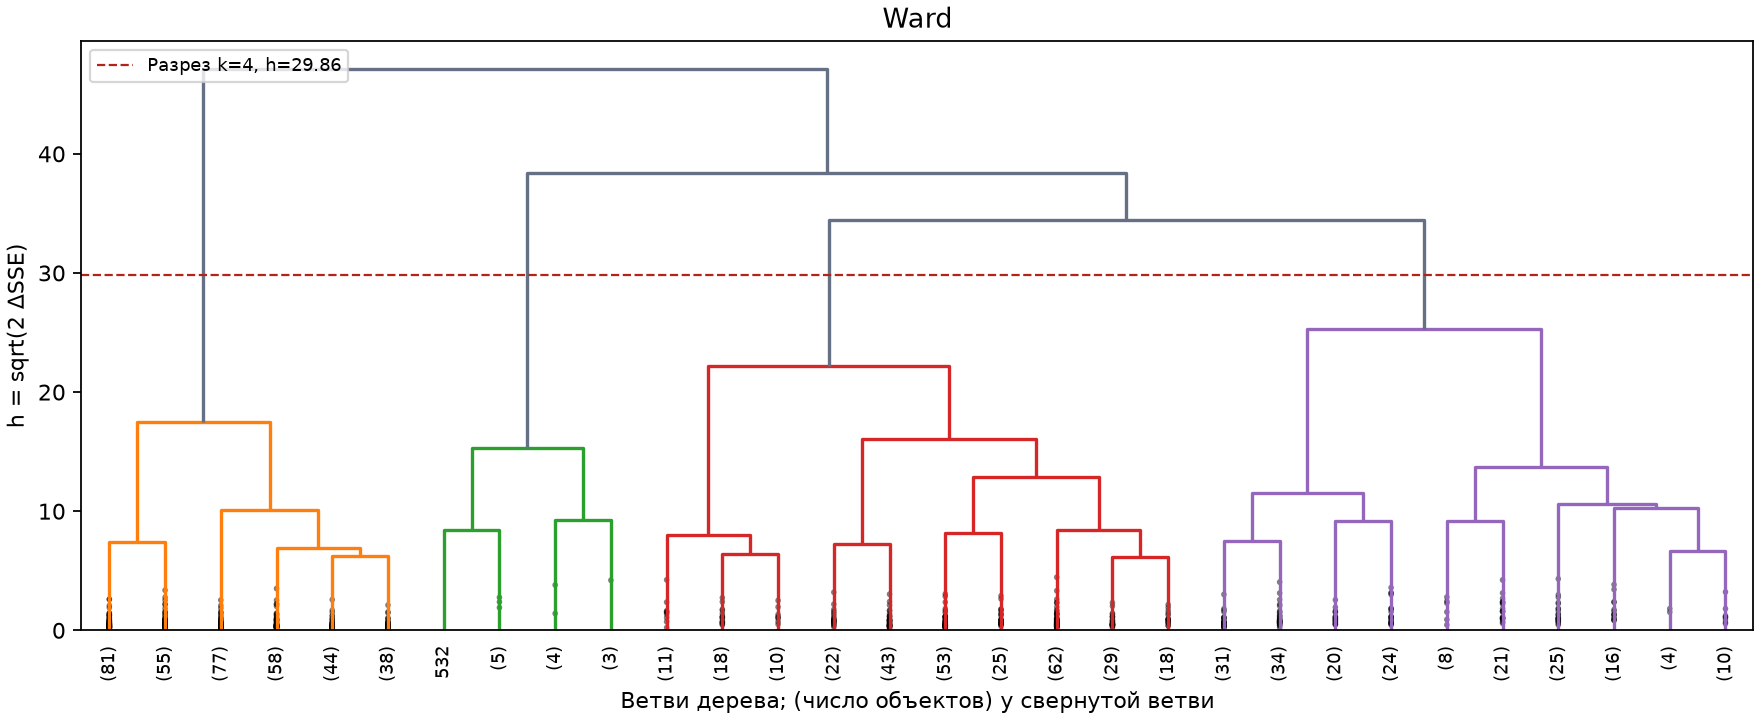

In [6]:
demo = cluster_dataset(frame, METHOD, K, FEATURE_COLUMNS)
display(pd.DataFrame([demo["metrics"]]).round(4))
plot_dendrogram(demo["Z"], METHOD, K)
demo_path = PROJECT/"demo_dendrogram.png"
plt.savefig(demo_path, dpi=160)
plt.close("all")
display(Image(filename=str(demo_path)))
demo_points = frame.copy()
demo_points["cluster"] = demo["labels"] + 1
demo_points.to_csv(PROJECT/"demo_points.csv", index=False)


## 5 Методика экспериментов и метрики

Строятся четыре дерева. Каждое разрезается при $k=3,\ldots,9$, поэтому изменение
числа кластеров не требует повторного обучения дерева. Случайной инициализации
у иерархического алгоритма нет. Сравнение с разделительными алгоритмами основано
на трех прежних зернах 2026, 2027, 2028 и пяти стартах в каждом запуске.

**SSE к центроидам** пересчитывается одинаково для всех разбиений:
$\sum_C\sum_{x\in C}\|x-\mu_C\|^2$. В прежней работе PAM минимизировал квадраты
расстояний до **медоидов**; поэтому его прежняя целевая функция сохраняется отдельно
в `sse_representative` и не подменяет общий критерий.

**Силуэт** характеризует разделимость объектов в 6D (слайд 67); для одиночной группы
силуэт объекта равен нулю. Высокий средний силуэт следует оценивать вместе с размерами
кластеров. **ARI** сравнивает два разбиения, учитывая случайные совпадения, и не
зависит от номеров групп. ARI не измеряет точность относительно истинных классов.
**Кофенетическая корреляция** сравнивает исходные попарные расстояния с высотами,
на которых пары впервые объединяются; она описывает дерево, а не полезность сегментов.


In [7]:
"""Эксперименты customers: 4 дерева, k=3..9 и сопоставление с прошлой работой.

Вход: DataFrame и архив результатов разделительной кластеризации.
Выход: CSV метрик и профилей, NPZ деревьев и меток, PNG визуализаций.
Сравнение использует сохраненные ранее метки, а не заменяет прежние алгоритмы.
"""
from pathlib import Path
import json
import time
import platform
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import cophenet, leaves_list
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import pdist, squareform
from sklearn.metrics import adjusted_rand_score

KS = list(range(3, 10))
SEEDS = [2026, 2027, 2028]
COLORS = np.array(["#2563a6", "#dc7b24", "#319276", "#ad4d82", "#8762ac", "#727c85", "#aa9429", "#3199ab", "#dd5656"])


def add_noise(X, fraction=0.10, seed=2026):
    """Вернуть X_noisy и маску измененных строк по схеме предыдущей работы.

    X: стандартизованные исходные данные; fraction: доля [0,1]; seed: зерно.
    Ровно floor(n*fraction+0.5) строк получают сдвиг одной координаты на
    ±U(3,6) исходных стандартных отклонений; повторной стандартизации нет.
    """
    if not np.isfinite(fraction) or not 0 <= fraction <= 1:
        raise ValueError("Доля шума должна находиться в [0,1]")
    rng = np.random.default_rng(seed)
    order = rng.permutation(len(X))
    cols = rng.integers(0, X.shape[1], size=len(X))
    shifts = rng.choice([-1.0, 1.0], len(X)) * rng.uniform(3.0, 6.0, len(X))
    count = int(np.floor(len(X) * fraction + 0.5))
    rows = order[:count]
    out = X.copy()
    out[rows, cols[:count]] += shifts[:count]
    mask = np.zeros(len(X), dtype=bool)
    mask[rows] = True
    return out, mask


def align_labels(reference, labels, k):
    """Перенумеровать labels по максимальному пересечению с reference.

    Вход: два вектора (n,), k меток 0..k-1; выход: выровненные метки (n,).
    Это меняет только цвета визуализации, но не состав кластеров и не ARI.
    """
    counts = np.zeros((k, k), dtype=int)
    np.add.at(counts, (reference, labels), 1)
    rows, cols = linear_sum_assignment(-counts)
    mapping = np.empty(k, dtype=int)
    mapping[cols] = rows
    return mapping[labels]


def run_experiments(frame, out, baseline_labels=None, baseline_metrics=None,
                    ks=KS, chosen_k=4, noise=True, features=None):
    """Построить четыре дерева и экспортировать воспроизводимые результаты.

    frame: исходные данные; out: каталог; baseline_labels: словарь массивов
    прежних меток; baseline_metrics: DataFrame прежних метрик; ks: разрезы;
    chosen_k: основной разрез; noise: дополнить тремя опытами с 10% шума.
    Архив прежних результатов следует передавать только для исходного CSV
    и того же порядка строк/признаков. Для другого набора передается None.
    Возвращает словарь X, preparation, trees, labels, metrics и comparisons.
    """
    out = Path(out)
    out.mkdir(parents=True, exist_ok=True)
    X, prep = prepare_data(frame, features)
    if not ks or min(ks) < 2 or max(ks) >= len(X) or chosen_k not in ks:
        raise ValueError("Нужны 2 <= k < n и chosen_k в ks")
    condensed = pdist(X)
    distances = squareform(condensed)
    trees, labels, records, comparisons, checks = {}, {}, [], [], []
    for method in METHODS:
        started = time.perf_counter()
        Z = agglomerative(X, method)
        elapsed = time.perf_counter() - started
        trees[method] = Z
        coph = float(cophenet(Z, condensed)[0])
        np.savetxt(out/f"linkage_{method}.csv", Z, delimiter=",",
                   header="left,right,height,count", comments="")
        for k in ks:
            lab = cut_exact(Z, k)
            labels[method, k] = lab
            stats = partition_stats(X, lab, distances)
            records.append(dict(method=method, **stats, cophenetic=coph,
                                tree_seconds=elapsed))
            if baseline_labels is not None:
                for algorithm in ["kmeans", "kmedoids"]:
                    for repeat, seed in enumerate(SEEDS):
                        key = f"{algorithm}_k{k}_p0.00_r{repeat}_labels"
                        comparisons.append(dict(method=method, k=k, algorithm=algorithm,
                            seed=seed, ari=adjusted_rand_score(lab, baseline_labels[key])))
        # Проверка дерева независимой реализацией SciPy не подменяет обучение.
        from scipy.cluster.hierarchy import linkage, is_valid_linkage
        ref = linkage(X, method=method, metric="euclidean")
        agree = [adjusted_rand_score(labels[method,k], cut_exact(ref,k)) for k in ks]
        delta = float(np.max(np.abs(Z[:,2] - ref[:,2])))
        if not is_valid_linkage(Z) or not np.allclose(Z[:,2],ref[:,2],atol=1e-10) or min(agree) < 1-1e-12:
            raise AssertionError(f"Расхождение со SciPy: {method}")
        checks.append(dict(method=method, height_max_error=delta, min_ari_vs_scipy=min(agree)))
        print(f"{NAMES[method]}: дерево {len(Z)} слияний, {elapsed:.2f} с", flush=True)
    metrics = pd.DataFrame(records)
    metrics.to_csv(out/"hierarchical_metrics.csv", index=False)
    pd.DataFrame(checks).to_csv(out/"scipy_validation.csv", index=False)
    points = frame.copy()
    for j, name in enumerate(prep["features"]):
        points["z_"+name] = X[:,j]
    packed = {"tree_"+method:Z for method,Z in trees.items()}
    for (method,k),lab in labels.items():
        packed[f"labels_{method}_k{k}"] = lab
        points[f"{method}_k{k}"] = lab+1
    points.to_csv(out/"all_points.csv", index=False)
    np.savez_compressed(out/"hierarchies.npz", **packed)
    (out/"preparation.json").write_text(json.dumps(prep, ensure_ascii=False, indent=2))
    result = dict(X=X, preparation=prep, trees=trees, labels=labels, metrics=metrics,
                  chosen_k=chosen_k, ks=ks, baseline_labels=baseline_labels,
                  baseline_metrics=baseline_metrics)
    if baseline_labels is not None:
        comparison = pd.DataFrame(comparisons)
        comparison.to_csv(out/"ari_to_partition.csv", index=False)
        result["comparisons"] = comparison
        baseline_rows = []
        for algorithm in ["kmeans", "kmedoids"]:
            for k in ks:
                for repeat, seed in enumerate(SEEDS):
                    lab = baseline_labels[f"{algorithm}_k{k}_p0.00_r{repeat}_labels"]
                    record = baseline_metrics.query("algorithm == @algorithm and k == @k and noise == 0 and repeat == @repeat").iloc[0]
                    stats = partition_stats(X, lab, distances)
                    if not np.isclose(stats["silhouette"], record.silhouette, atol=1e-10):
                        raise AssertionError("Архив не соответствует данным и подготовке")
                    baseline_rows.append(dict(algorithm=algorithm, seed=seed, **stats,
                        sse_representative=float(record.sse)))
        result["baseline"] = pd.DataFrame(baseline_rows)
        result["baseline"].to_csv(out/"partition_recomputed.csv", index=False)
    names = list(METHODS)
    labs = [labels[m,chosen_k] for m in METHODS]
    if baseline_labels is not None:
        names += ["kmeans", "kmedoids"]
        labs += [baseline_labels[f"{a}_k{chosen_k}_p0.00_r0_labels"] for a in ["kmeans","kmedoids"]]
    ari = pd.DataFrame([[adjusted_rand_score(a,b) for b in labs] for a in labs],index=names,columns=names)
    ari.to_csv(out/"pairwise_ari_k4.csv")
    result["pairwise_ari"] = ari
    raw = frame[prep["features"]].apply(pd.to_numeric).fillna(dict(zip(prep["features"],prep["median"])))
    lab = labels["ward",chosen_k]
    profile = raw.assign(cluster=lab+1).groupby("cluster").mean()
    profile.insert(0,"n",np.bincount(lab))
    profile.to_csv(out/"ward_profiles.csv")
    zprofile = pd.DataFrame(X,columns=prep["features"]).assign(cluster=lab+1).groupby("cluster").mean()
    zprofile.to_csv(out/"ward_profiles_z.csv")
    result["profiles"], result["profiles_z"] = profile, zprofile
    if noise:
        noise_rows, noise_points = [], []
        for repeat, seed in enumerate(SEEDS):
            noisy, mask = add_noise(X,.1,seed)
            noisy_distances = squareform(pdist(noisy))
            for method in METHODS:
                lab = cut_exact(agglomerative(noisy,method),chosen_k)
                stats = partition_stats(noisy,lab,noisy_distances)
                noise_rows.append(dict(algorithm=method,seed=seed,noise=.1,changed_rows=int(mask.sum()),
                    ari_intact=adjusted_rand_score(labels[method,chosen_k][~mask],lab[~mask]), **stats))
                noise_points.append(pd.DataFrame(dict(algorithm=method,seed=seed,
                    object_index=np.arange(len(X)),is_noisy=mask,cluster=lab+1)))
            if baseline_labels is not None:
                for algorithm in ["kmeans","kmedoids"]:
                    clean = baseline_labels[f"{algorithm}_k{chosen_k}_p0.00_r{repeat}_labels"]
                    lab = baseline_labels[f"{algorithm}_k{chosen_k}_p0.10_r{repeat}_labels"]
                    stats = partition_stats(noisy,lab,noisy_distances)
                    ari_intact = adjusted_rand_score(clean[~mask],lab[~mask])
                    old = baseline_metrics.query("algorithm == @algorithm and k == @chosen_k and noise == 0.1 and repeat == @repeat").iloc[0]
                    if not np.isclose(ari_intact,old.ari_intact):
                        raise AssertionError("Не совпадает схема шума с прошлой работой")
                    noise_rows.append(dict(algorithm=algorithm,seed=seed,noise=.1,changed_rows=int(mask.sum()),
                                           ari_intact=ari_intact,**stats))
            print(f"Шум 10%, seed={seed}: проверено",flush=True)
        result["noise"] = pd.DataFrame(noise_rows)
        result["noise"].to_csv(out/"noise_metrics.csv",index=False)
        pd.concat(noise_points,ignore_index=True).to_csv(out/"noise_labels.csv",index=False)
    import scipy, sklearn, matplotlib
    versions = dict(python=platform.python_version(),numpy=np.__version__,pandas=pd.__version__,
                    scipy=scipy.__version__,sklearn=sklearn.__version__,matplotlib=matplotlib.__version__)
    (out/"versions.json").write_text(json.dumps(versions,indent=2))
    return result


def make_figures(result, out):
    """Сохранить дендрограммы, показатели, ARI, PCA, профили и шум в out.

    result: выход run_experiments. PCA обучается один раз на исходной X;
    метрики вычислены в полном пространстве. Цвета разбиений согласованы
    с исходным k-Means seed=2026, если его метки доступны, иначе с Ward.
    """
    out = Path(out)
    out.mkdir(parents=True,exist_ok=True)
    plt.rcParams.update({"font.family":"DejaVu Sans","font.size":10,
        "figure.dpi":120,"savefig.dpi":200,"axes.spines.top":False,
        "axes.spines.right":False,"axes.grid":True,"grid.alpha":.15})
    k=result["chosen_k"];X=result["X"];metrics=result["metrics"]
    fig,axes=plt.subplots(2,2,figsize=(12,8.5),layout="constrained")
    for ax,method in zip(axes.flat,METHODS):
        plot_dendrogram(result["trees"][method],method,k,ax,30)
    fig.savefig(out/"dendrograms.png");plt.close(fig)
    for method in METHODS:
        plot_dendrogram(result["trees"][method],method,k,truncate=None)
        plt.savefig(out/f"dendrogram_full_{method}.png");plt.close("all")
    fig,axes=plt.subplots(1,2,figsize=(11,4),layout="constrained")
    for i,method in enumerate(METHODS):
        s=metrics[metrics.method==method].sort_values("k")
        axes[0].plot(s.k,s.sse_centroid,"o-",label=NAMES[method],color=COLORS[i])
        axes[1].plot(s.k,s.silhouette,"o-",label=NAMES[method],color=COLORS[i])
    if "baseline" in result:
        for i,a in enumerate(["kmeans","kmedoids"]):
            s=result["baseline"].query("algorithm == @a").groupby("k").mean(numeric_only=True)
            for ax,field in zip(axes,["sse_centroid","silhouette"]):
                ax.plot(s.index,s[field],"s--",label={"kmeans":"k-Means","kmedoids":"k-Medoids"}[a],color=COLORS[i+4])
    for ax in axes:ax.set(xlabel="Число кластеров k",xticks=result["ks"]);ax.legend(fontsize=8)
    axes[0].set(title="Компактность разбиения",ylabel="SSE относительно центроидов")
    axes[1].set(title="Разделимость в полном пространстве",ylabel="Средний силуэт")
    fig.savefig(out/"metrics_by_k.png");plt.close(fig)
    fig,ax=plt.subplots(figsize=(10,3.5),layout="constrained")
    for i,m in enumerate(METHODS):
        sizes=sorted(np.bincount(result["labels"][m,k]),reverse=True)
        start=0
        for j,count in enumerate(sizes):
            ax.barh(i,count,left=start,color=COLORS[j],edgecolor="white",height=.65)
            if count>25:ax.text(start+count/2,i,str(count),ha="center",va="center",color="white",weight="bold")
            start+=count
        ax.text(len(X)+10,i," / ".join(map(str,sizes)),va="center",fontsize=9)
    ax.set(yticks=range(4),yticklabels=[NAMES[m] for m in METHODS],xlabel="Число объектов",xlim=(0,len(X)*1.36),title=f"Размеры кластеров при k={k}")
    ax.invert_yaxis();fig.savefig(out/"cluster_sizes.png");plt.close(fig)
    fig,ax=plt.subplots(figsize=(7,5.3),layout="constrained")
    A=result["pairwise_ari"]
    labels=[NAMES.get(a,{"kmeans":"k-Means","kmedoids":"k-Medoids"}.get(a,a)) for a in A.index]
    im=ax.imshow(A,vmin=0,vmax=1,cmap="Blues")
    for i in range(len(A)):
        for j in range(len(A)):ax.text(j,i,f"{A.iloc[i,j]:.3f}",ha="center",va="center",color="white" if A.iloc[i,j]>.6 else "black",fontsize=13)
    ax.set(xticks=range(len(A)),xticklabels=labels,yticks=range(len(A)),yticklabels=labels,title=f"Согласованность разбиений ARI при k={k}")
    ax.tick_params(axis="x",labelrotation=28,labelsize=11)
    ax.tick_params(axis="y",labelsize=11);ax.grid(False)
    fig.colorbar(im,ax=ax,label="ARI");fig.savefig(out/"pairwise_ari.png");plt.close(fig)
    mean=X.mean(axis=0);_,singular,vt=np.linalg.svd(X-mean,full_matrices=False)
    ratio=singular[:2]**2/np.sum(singular**2)
    xy=(X-mean)@vt[:2].T
    names=list(METHODS);labs=[result["labels"][m,k] for m in METHODS]
    baseline=result["baseline_labels"]
    if baseline is not None:
        names += ["kmeans","kmedoids"]
        labs += [baseline[f"{a}_k{k}_p0.00_r0_labels"] for a in ["kmeans","kmedoids"]]
    reference=labs[-2] if baseline is not None else result["labels"]["ward",k]
    fig,axes=plt.subplots(3 if len(names)>4 else 2,2,figsize=(10,10 if len(names)>4 else 7),sharex=True,sharey=True,layout="constrained")
    for ax,name,lab in zip(axes.flat,names,labs):
        aligned=align_labels(reference,lab,k)
        ax.scatter(xy[:,0],xy[:,1],c=COLORS[aligned],s=12,alpha=.72,linewidths=0)
        ax.set(title=NAMES.get(name,{"kmeans":"k-Means","kmedoids":"k-Medoids"}.get(name,name)),
               xlabel=f"PC1 ({ratio[0]:.1%})",ylabel=f"PC2 ({ratio[1]:.1%})")
    fig.savefig(out/"pca_partitions.png");plt.close(fig)
    (out.parent/"pca.json").write_text(json.dumps(dict(explained_ratio=ratio.tolist(),total=float(ratio.sum())),indent=2))
    fig,ax=plt.subplots(figsize=(9,3.3),layout="constrained")
    P=result["profiles_z"]
    vmax=max(float(np.abs(P.to_numpy()).max()),1)
    im=ax.imshow(P,aspect="auto",cmap="RdBu_r",vmin=-vmax,vmax=vmax)
    for i in range(len(P)):
        for j in range(len(P.columns)):ax.text(j,i,f"{P.iloc[i,j]:.2f}",ha="center",va="center",color="white" if abs(P.iloc[i,j])>vmax*.6 else "black",fontsize=9)
    ax.set(xticks=range(len(P.columns)),xticklabels=P.columns,yticks=range(len(P)),
           yticklabels=[f"Кластер {i} (n={int(result['profiles'].loc[i,'n'])})" for i in P.index],title=f"Средние стандартизованные признаки Ward при k={k}")
    ax.tick_params(axis="x",labelrotation=15);ax.grid(False);fig.colorbar(im,ax=ax,label="Среднее z")
    fig.savefig(out/"ward_profiles.png");plt.close(fig)
    if "noise" in result:
        s=result["noise"].groupby("algorithm").ari_intact.agg(["mean","std"])
        order=list(s.index)
        fig,ax=plt.subplots(figsize=(9,3.8),layout="constrained")
        ax.bar(range(len(s)),s["mean"],yerr=s["std"],capsize=4,color=[COLORS[(list(METHODS)+["kmeans","kmedoids"]).index(a)] for a in order])
        ax.set(xticks=range(len(s)),xticklabels=[NAMES.get(a,{"kmeans":"k-Means","kmedoids":"k-Medoids"}.get(a,a)) for a in order],ylabel="ARI неизмененных объектов",ylim=(-.05,1.10),title=f"Устойчивость при 10% шума и k={k}\nСреднее ± стандартное отклонение по трем зернам")
        ax.tick_params(axis="x",labelrotation=15)
        fig.savefig(out/"noise_stability.png");plt.close(fig)


In [8]:
baseline_labels = dict(np.load(PROJECT/"data/partition_models.npz")) if is_original else None
baseline_metrics = pd.read_csv(PROJECT/"data/partition_metrics.csv") if is_original else None
result = run_experiments(frame, PROJECT/"results", baseline_labels, baseline_metrics,
                         ks=KS, chosen_k=K, noise=RUN_NOISE_EXPERIMENT, features=FEATURE_COLUMNS)
make_figures(result, PROJECT/"results/figures")
display(result["metrics"].query("k == @K").round(4))
display(pd.read_csv(PROJECT/"results/scipy_validation.csv"))


Single linkage: дерево 849 слияний, 0.33 с
Complete linkage: дерево 849 слияний, 0.33 с
Group average: дерево 849 слияний, 0.33 с
Ward: дерево 849 слияний, 0.34 с
Шум 10%, seed=2026: проверено
Шум 10%, seed=2027: проверено
Шум 10%, seed=2028: проверено


,method,k,sse_centroid,silhouette,min_size,max_size,singletons,sizes,cophenetic,tree_seconds
1,single,4,4699.4989,0.6693,1,847,3,847 / 1 / 1 / 1,0.8716,0.3331
8,complete,4,3445.3628,0.4120,6,765,0,765 / 72 / 7 / 6,0.8111,0.3306
15,average,4,4304.5764,0.6784,1,842,1,842 / 4 / 3 / 1,0.8529,0.3330
22,ward,4,2661.2603,0.2325,13,353,0,353 / 291 / 193 / 13,0.3809,0.3379


,method,height_max_error,min_ari_vs_scipy
0,single,0.000000e+00,1.0
1,complete,0.000000e+00,1.0
2,average,1.776357e-15,1.0
3,ward,1.421085e-14,1.0


## 6 Сравнение мер связи

Для исходного customers при k=4 Single дает размеры 847/1/1/1, Group average —
842/4/3/1, Complete — 765/72/7/6, Ward — 353/291/193/13. У Single и Group average
большинство клиентов остается в одном кластере, а удаленные объекты образуют
малые группы. Поэтому их силуэты 0,669 и 0,678 не доказывают удачную сегментацию.
Ward дает меньшую SSE среди четырех иерархических методов, но уступает по ней
k-Means. Это ожидаемо: Ward делает необратимые локальные слияния и не переносит
объекты между уже сформированными группами.

Эти числа относятся к вложенному customers и k=4. При смене файла или параметров
ориентируйтесь на вычисленные таблицы и рисунки.


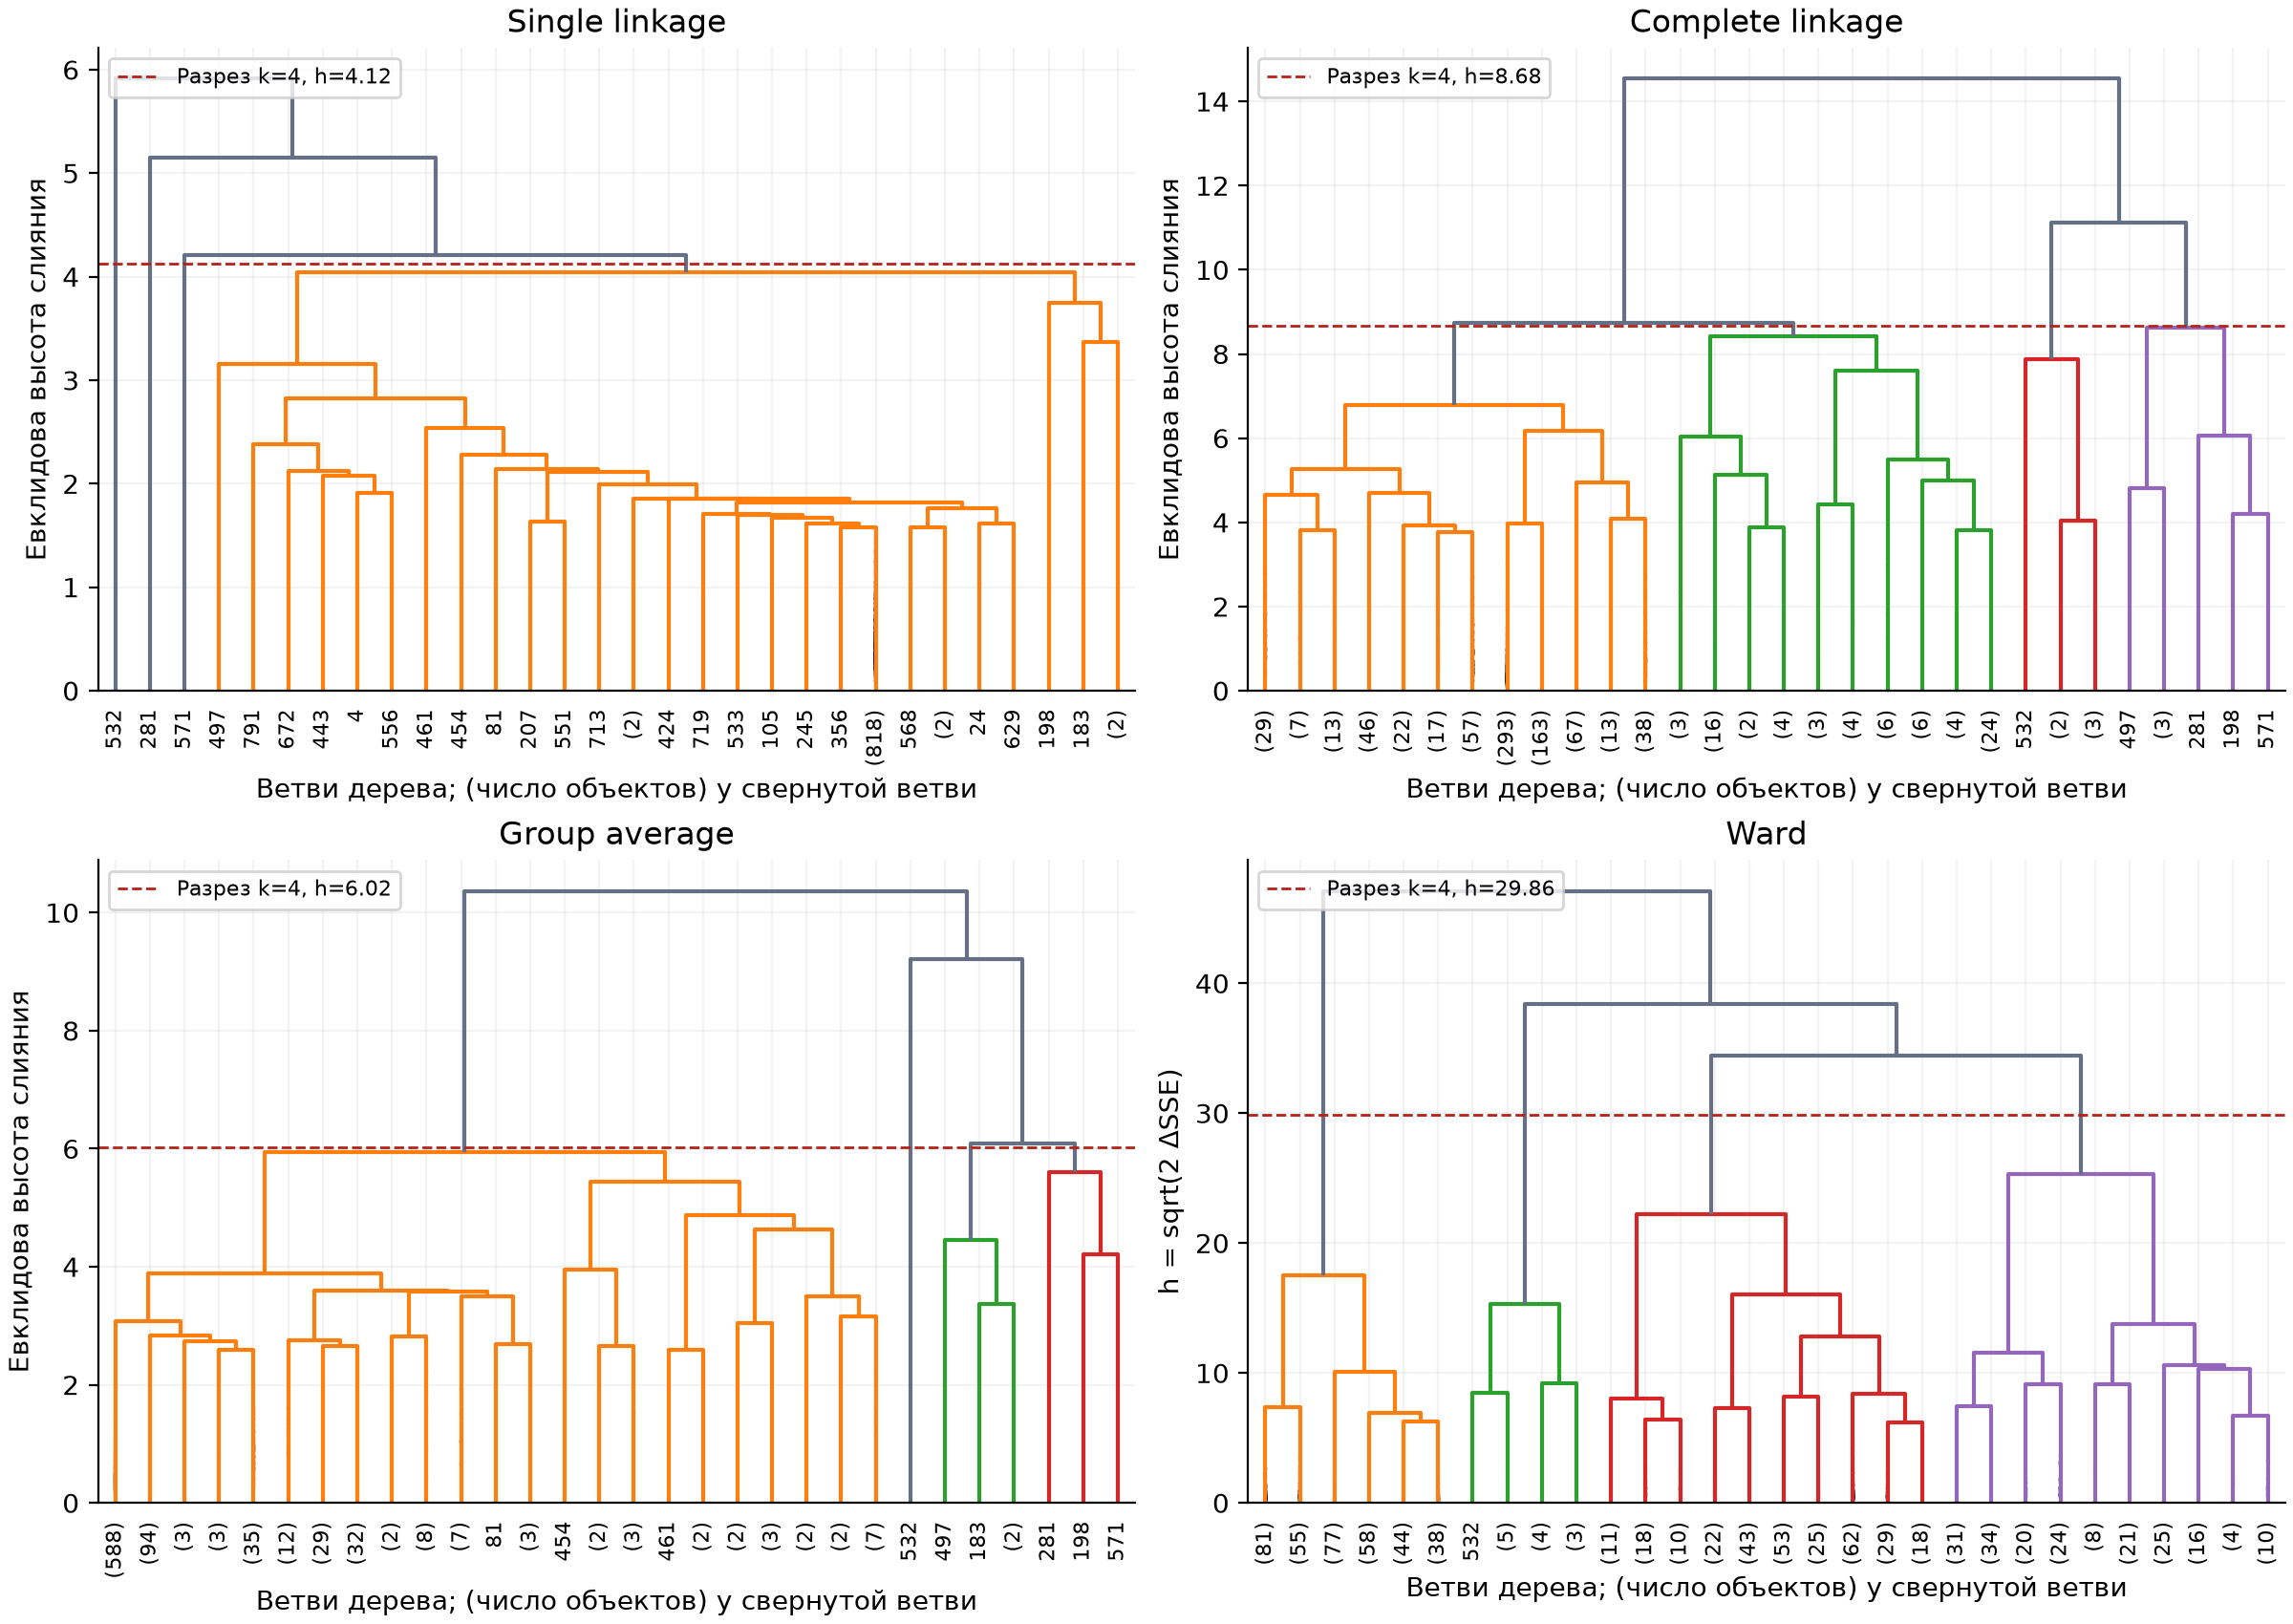

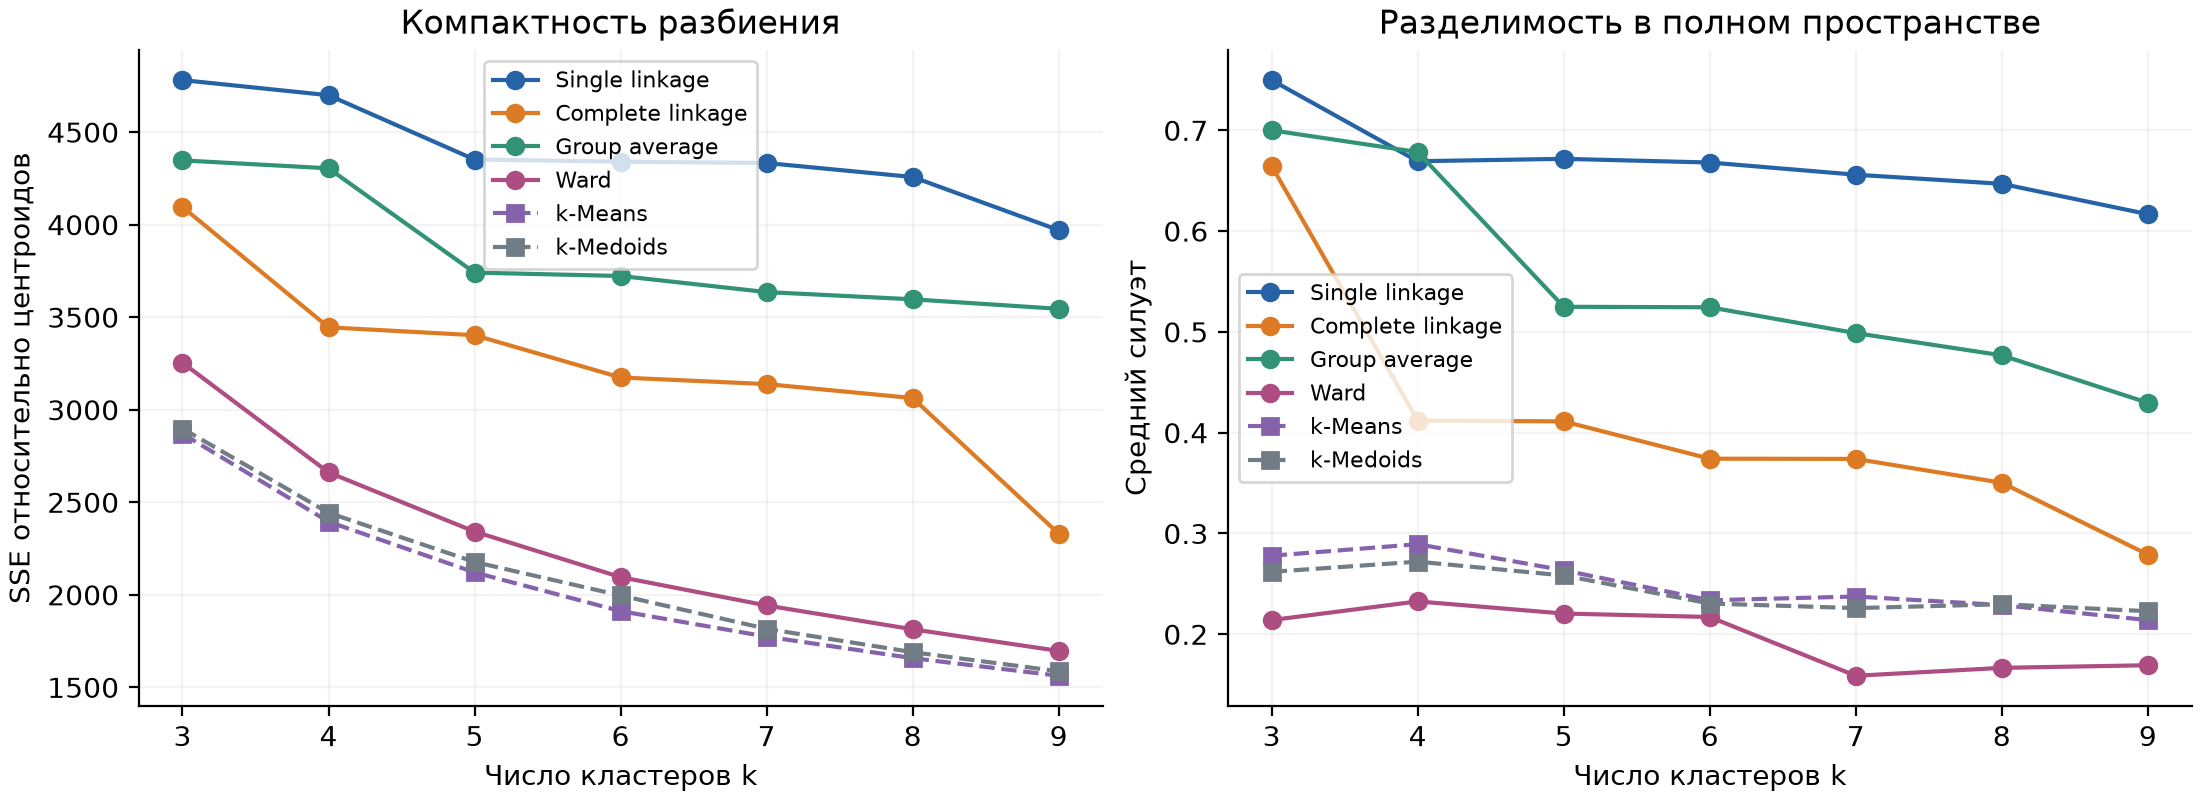

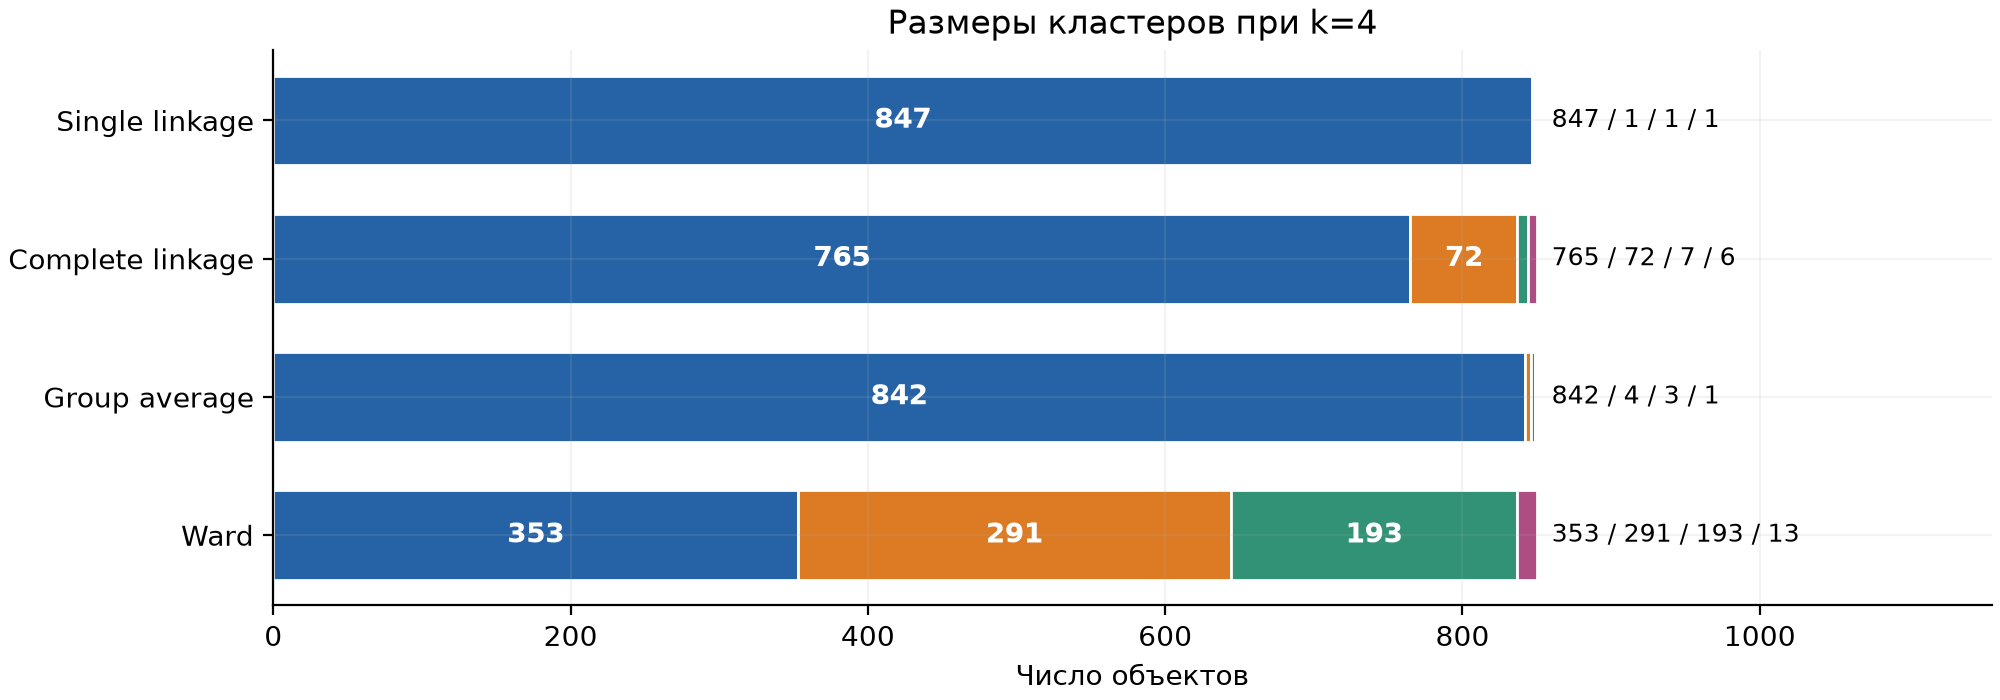

,method,k,sse_centroid,silhouette,sizes
0,single,3,4781.0475,0.7498,848 / 1 / 1
1,single,4,4699.4989,0.6693,847 / 1 / 1 / 1
2,single,5,4351.9799,0.6717,843 / 4 / 1 / 1 / 1
3,single,6,4340.3428,0.6680,843 / 3 / 1 / 1 / 1 / 1
4,single,7,4333.1024,0.6559,843 / 2 / 1 / 1 / 1 / 1 / 1
5,single,8,4257.4858,0.6469,842 / 2 / 1 / 1 / 1 / 1 / 1 / 1
6,single,9,3970.2797,0.6167,837 / 5 / 2 / 1 / 1 / 1 / 1 / 1 / 1
7,complete,3,4095.7012,0.6646,837 / 7 / 6
8,complete,4,3445.3628,0.4120,765 / 72 / 7 / 6
9,complete,5,3402.7284,0.4112,765 / 72 / 6 / 4 / 3


In [9]:
for figure in ["dendrograms.png", "metrics_by_k.png", "cluster_sizes.png"]:
    display(Image(filename=str(PROJECT/"results/figures"/figure)))
display(result["metrics"][["method","k","sse_centroid","silhouette","sizes"]].round(4))


## 7 Сравнение с разделительной кластеризацией

Для customers средняя SSE к центроидам при k=4 равна 2395,03 у k-Means,
2443,14 у k-Medoids и 2661,26 у Ward. Прежняя SSE к медоидам равна 2567,11.
Ward ближе к предыдущим разбиениям, чем остальные меры связи: средний ARI с
k-Means составляет 0,450, с k-Medoids — 0,539.

На матрице ARI и PCA показаны прежние запуски с seed=2026. Номера и цвета групп
сопоставлены по максимальному пересечению. Цвет одинакового номера не означает
полного совпадения состава. Две компоненты PCA объясняют 75,56% дисперсии;
перекрытие проекций не равносильно совпадению точек в шести измерениях.


sse_centroid       sse_representative       silhouette        
                  mean   std               mean   std       mean     std
algorithm                                                               
kmeans       2395.0252  0.01          2395.0252  0.01     0.2893  0.0001
kmedoids     2443.1439  0.00          2567.1102  0.00     0.2720  0.0000

mean     std
method   algorithm                
average  kmeans     0.0171  0.0000
         kmedoids   0.0151  0.0000
complete kmeans     0.1406  0.0004
         kmedoids   0.1159  0.0000
single   kmeans     0.0063  0.0000
         kmedoids   0.0056  0.0000
ward     kmeans     0.4504  0.0016
         kmedoids   0.5385  0.0000

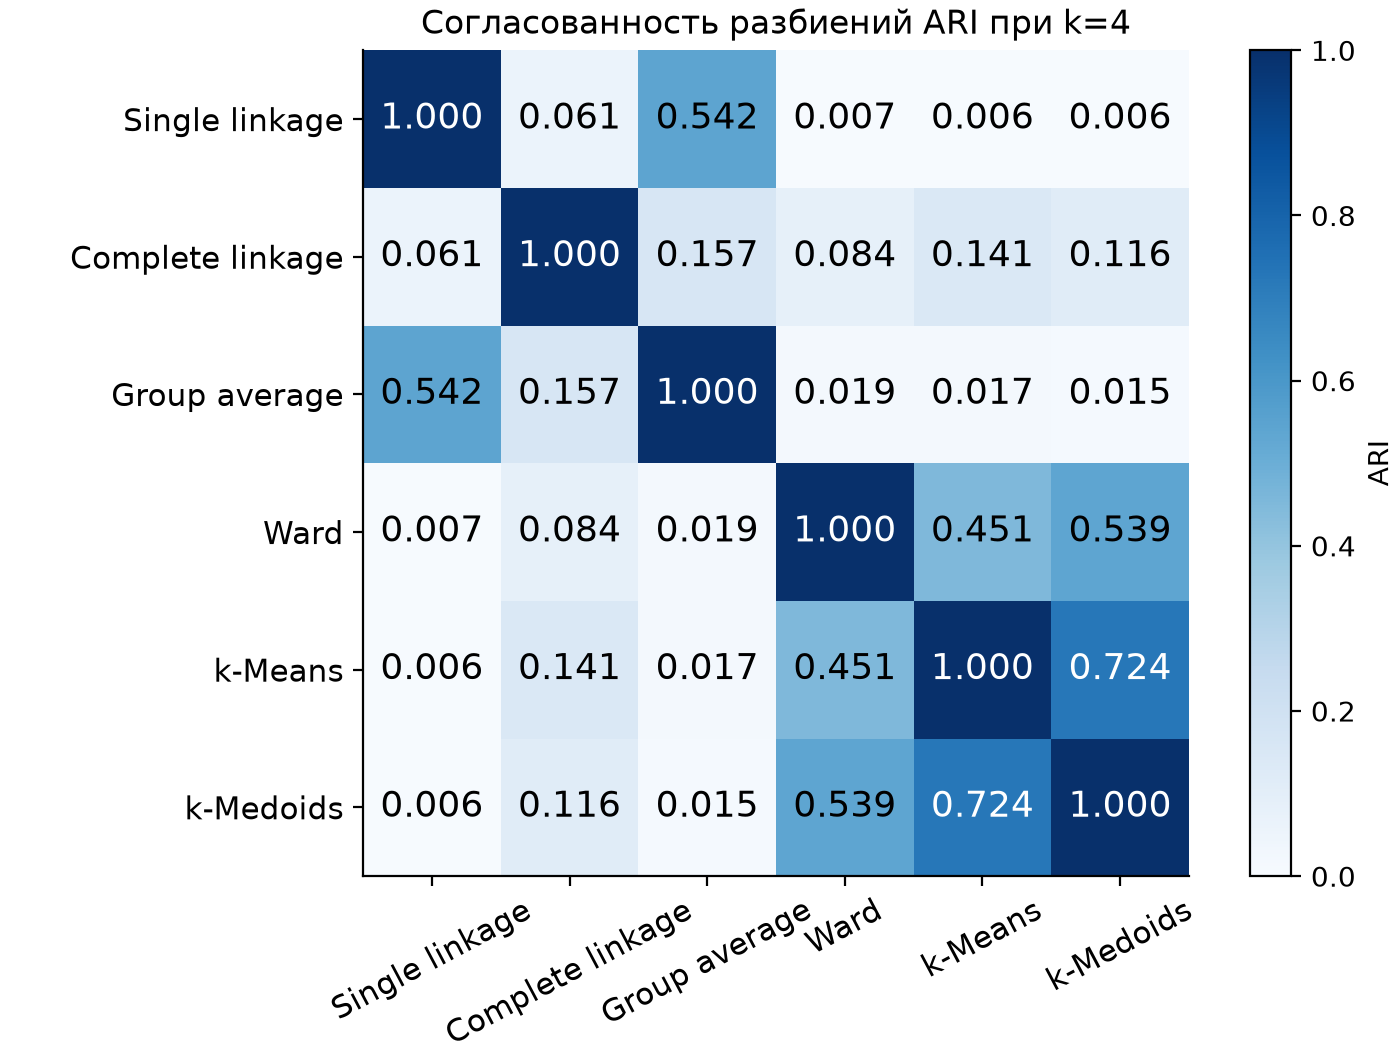

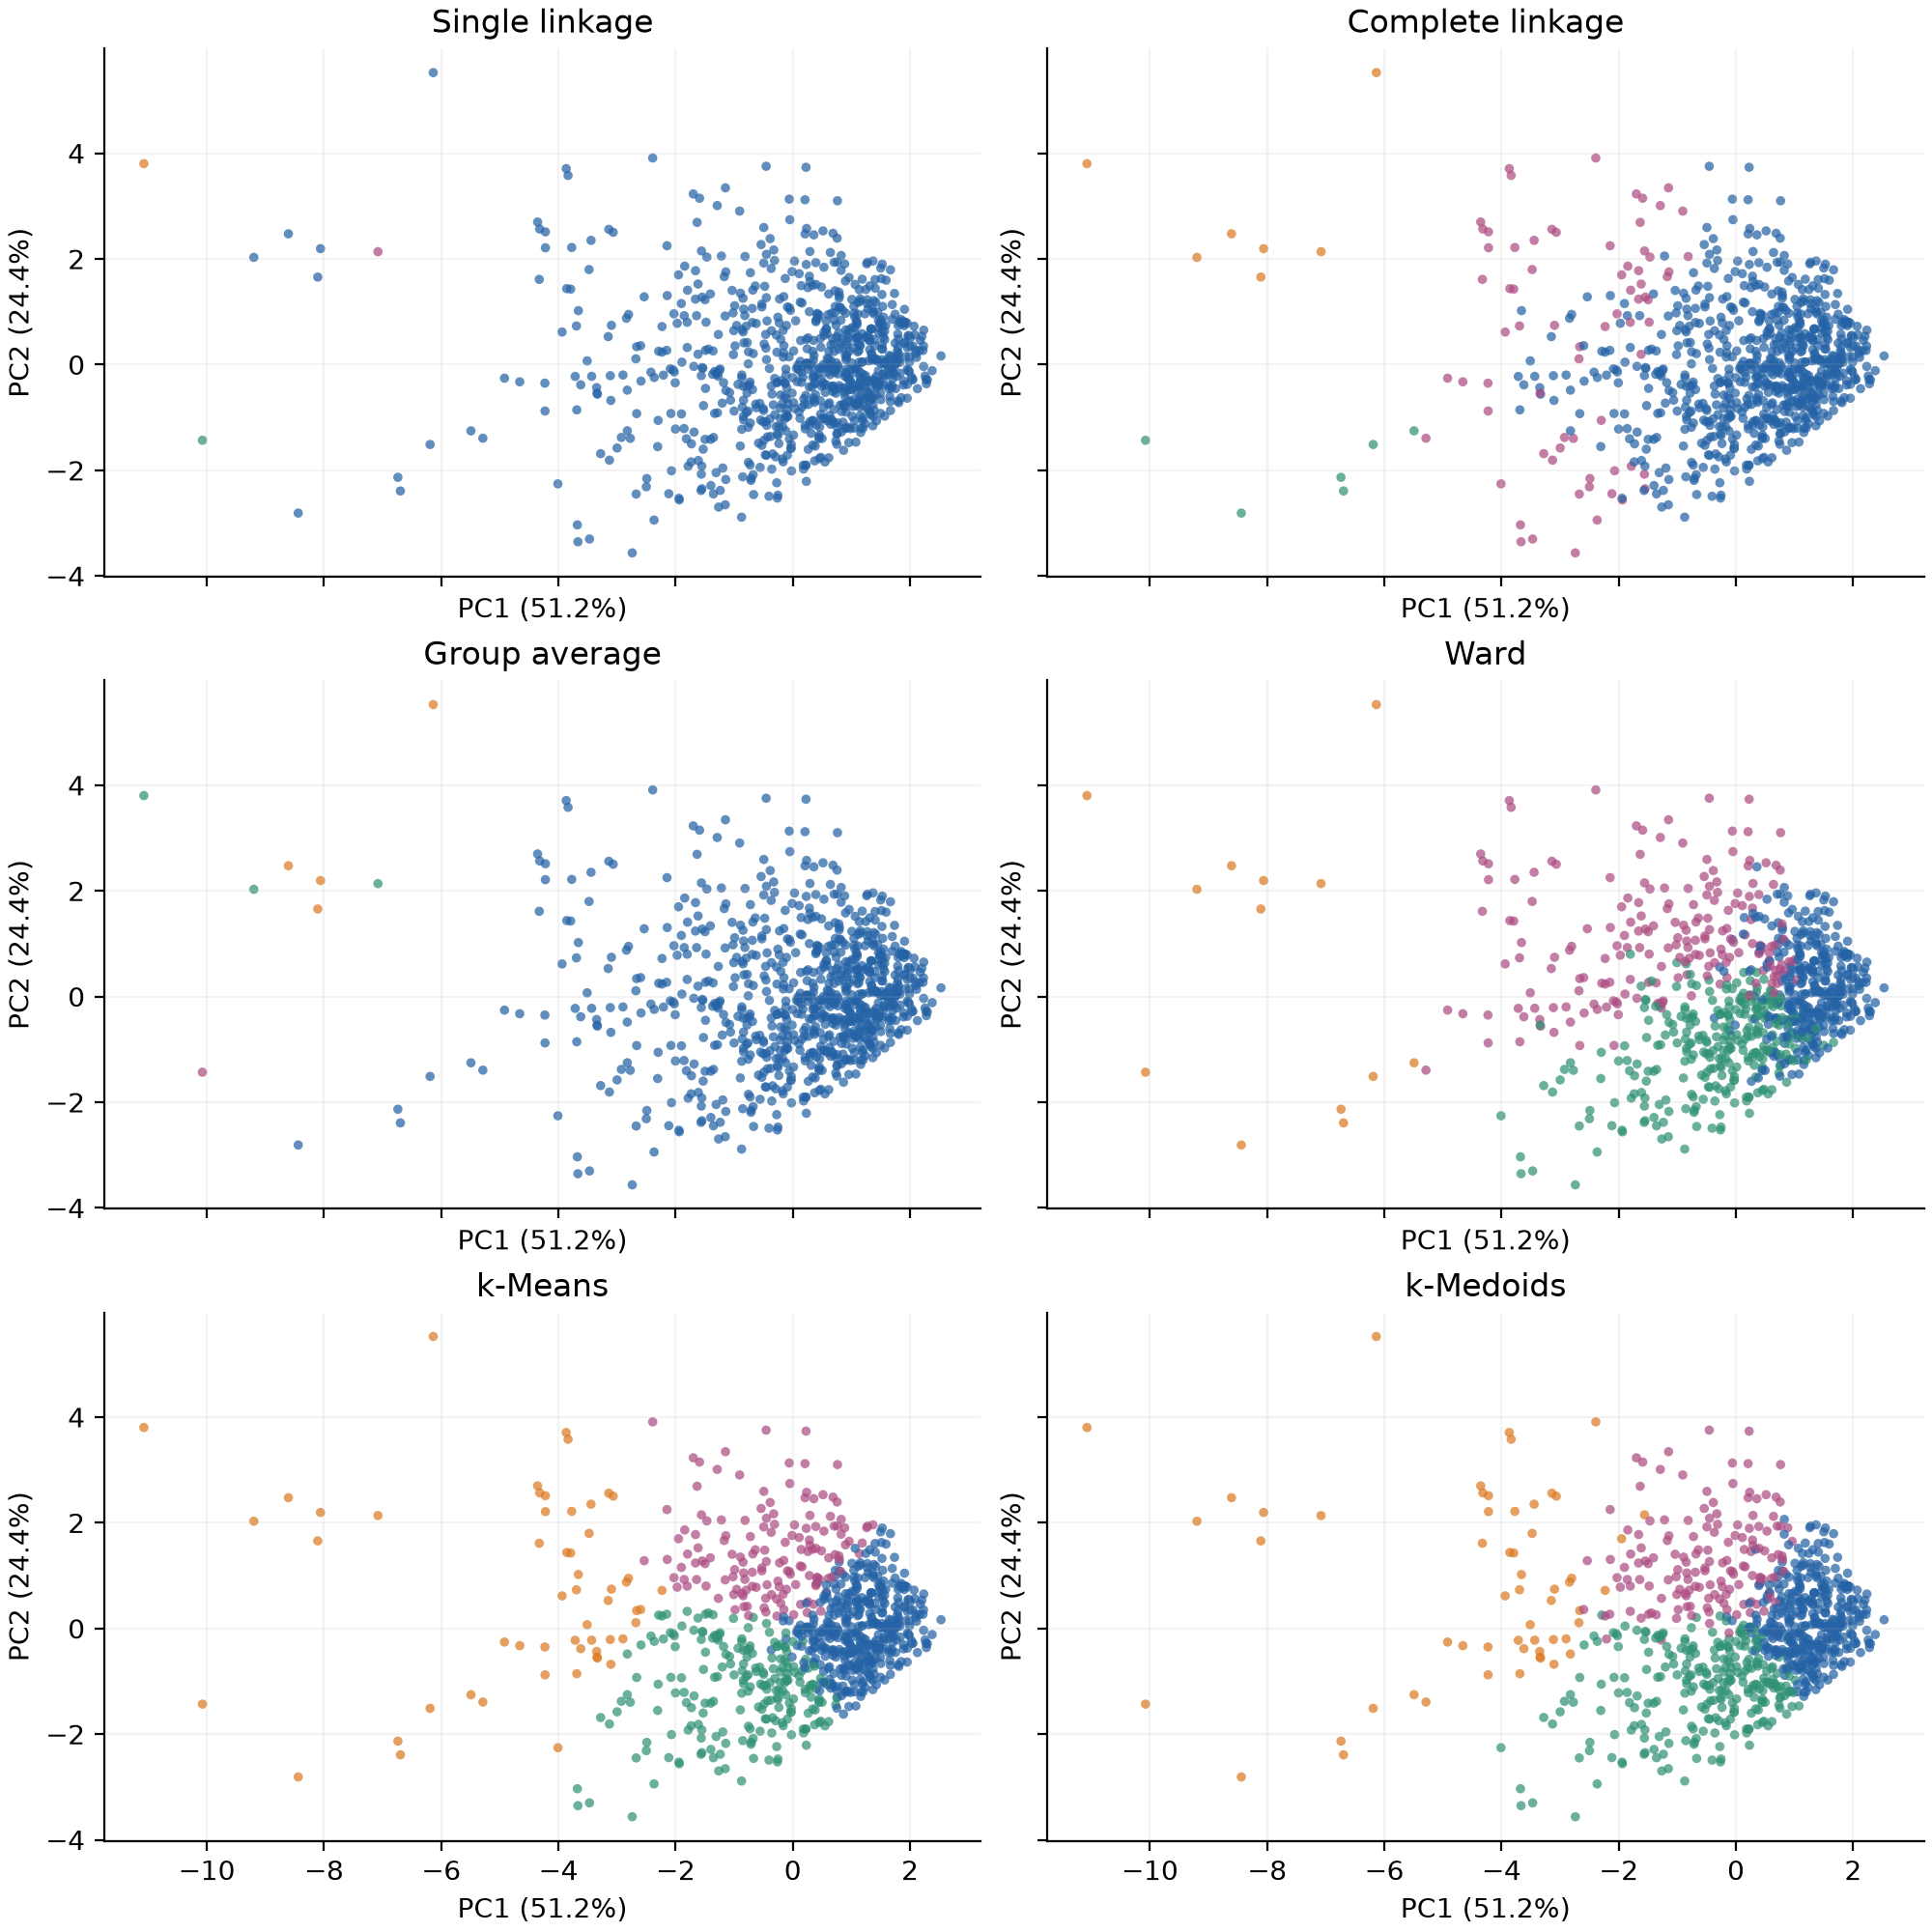

In [10]:
if "baseline" in result:
    display(result["baseline"].query("k == @K").groupby("algorithm")[["sse_centroid","sse_representative","silhouette"]].agg(["mean","std"]).round(4))
    display(result["comparisons"].query("k == @K").groupby(["method","algorithm"]).ari.agg(["mean","std"]).round(4))
display(Image(filename=str(PROJECT/"results/figures/pairwise_ari.png")))
display(Image(filename=str(PROJECT/"results/figures/pca_partitions.png")))


## 8 Смысл кластеров Ward

Для исходного customers кластер 1 включает 291 клиента с большим стажем и умеренной
долговой нагрузкой; кластер 2 — 193 клиента с более высокой долговой нагрузкой;
кластер 3 — 353 более молодых клиента с меньшими доходами и стажем; кластер 4 —
13 клиентов с очень высокими доходами и абсолютными долгами. Это описания средних
профилей, а не оценки кредитного риска: Defaulted в модели не используется.


,n,Age,YearsEmployed,Income,CardDebt,OtherDebt,DebtIncomeRatio
cluster,,,,,,,
1,291,40.973,12.326,57.715,1.281,2.423,7.166
2,193,37.440,9.347,53.399,3.080,6.120,18.420
3,353,28.382,4.504,27.663,0.624,1.440,7.874
4,13,46.692,23.077,216.000,11.767,17.104,17.400


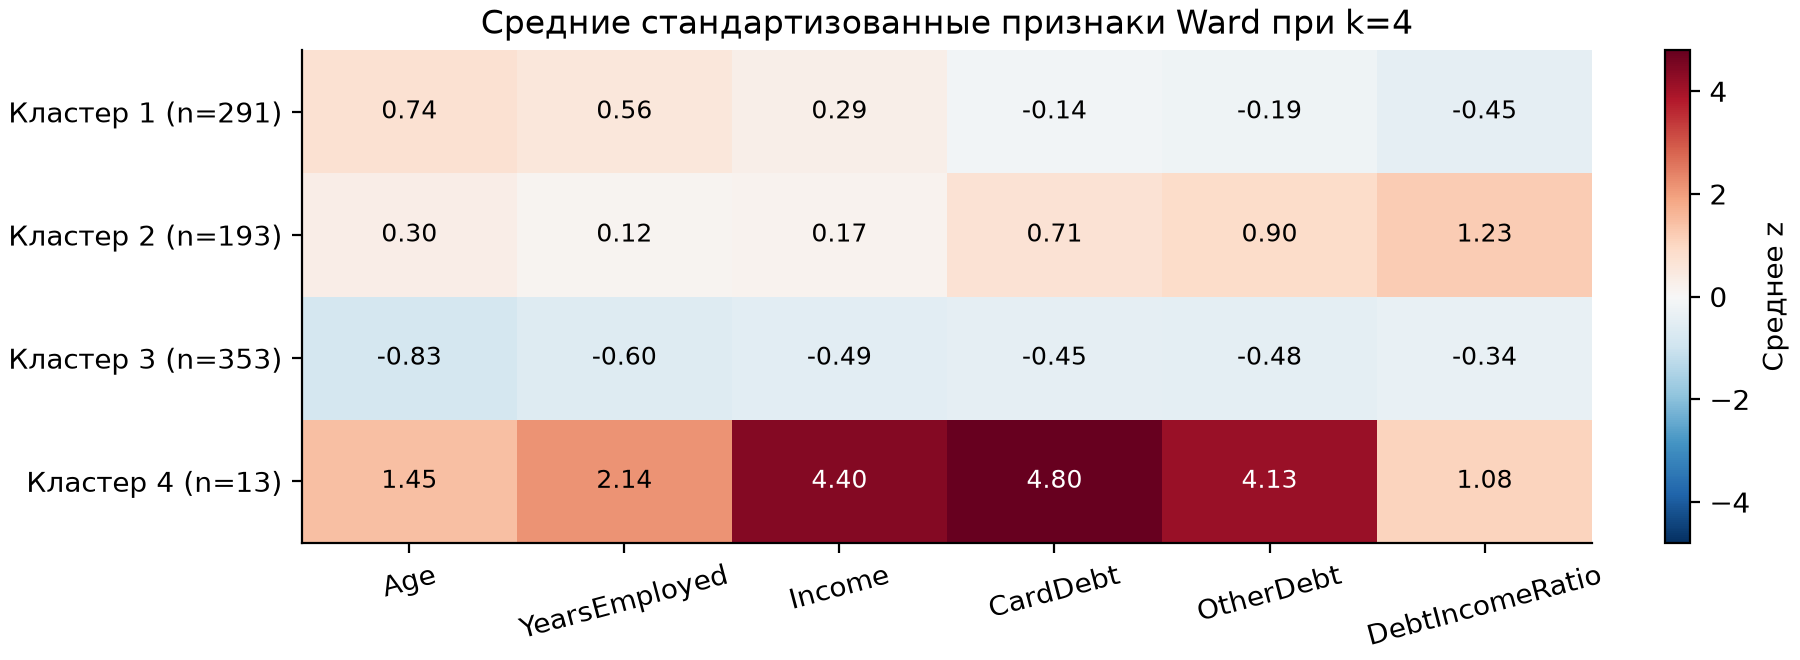

In [11]:
display(result["profiles"].round(3))
display(Image(filename=str(PROJECT/"results/figures/ward_profiles.png")))


## 9 Дополнительная проверка устойчивости

В точности повторяется схема предыдущей работы: 10% из 850 строк, то есть 85,
получают сдвиг одной координаты на ±U(3,6) исходных стандартных отклонений.
Для каждого зерна все методы получают одинаковое искажение; масштаб фиксирован.
ARI вычисляется на 765 неизмененных объектах относительно чистого разбиения
того же метода. На графике среднее ± стандартное отклонение трех зерен.

Для customers средний ARI Ward равен 0,502, k-Means — 0,966, k-Medoids — 0,913.
Высокая устойчивость Group average 0,910 сопровождается сохранением почти одной
большой группы. Устойчивость сама по себе также не доказывает полезность разбиения.
Три зерна описывают этот эксперимент, а не гарантируют поведение на любых данных.


,mean,std
algorithm,,
average,0.9098,0.1546
complete,0.2470,0.0690
kmeans,0.9663,0.0070
kmedoids,0.9127,0.0760
single,0.7102,0.0769
ward,0.5020,0.1101


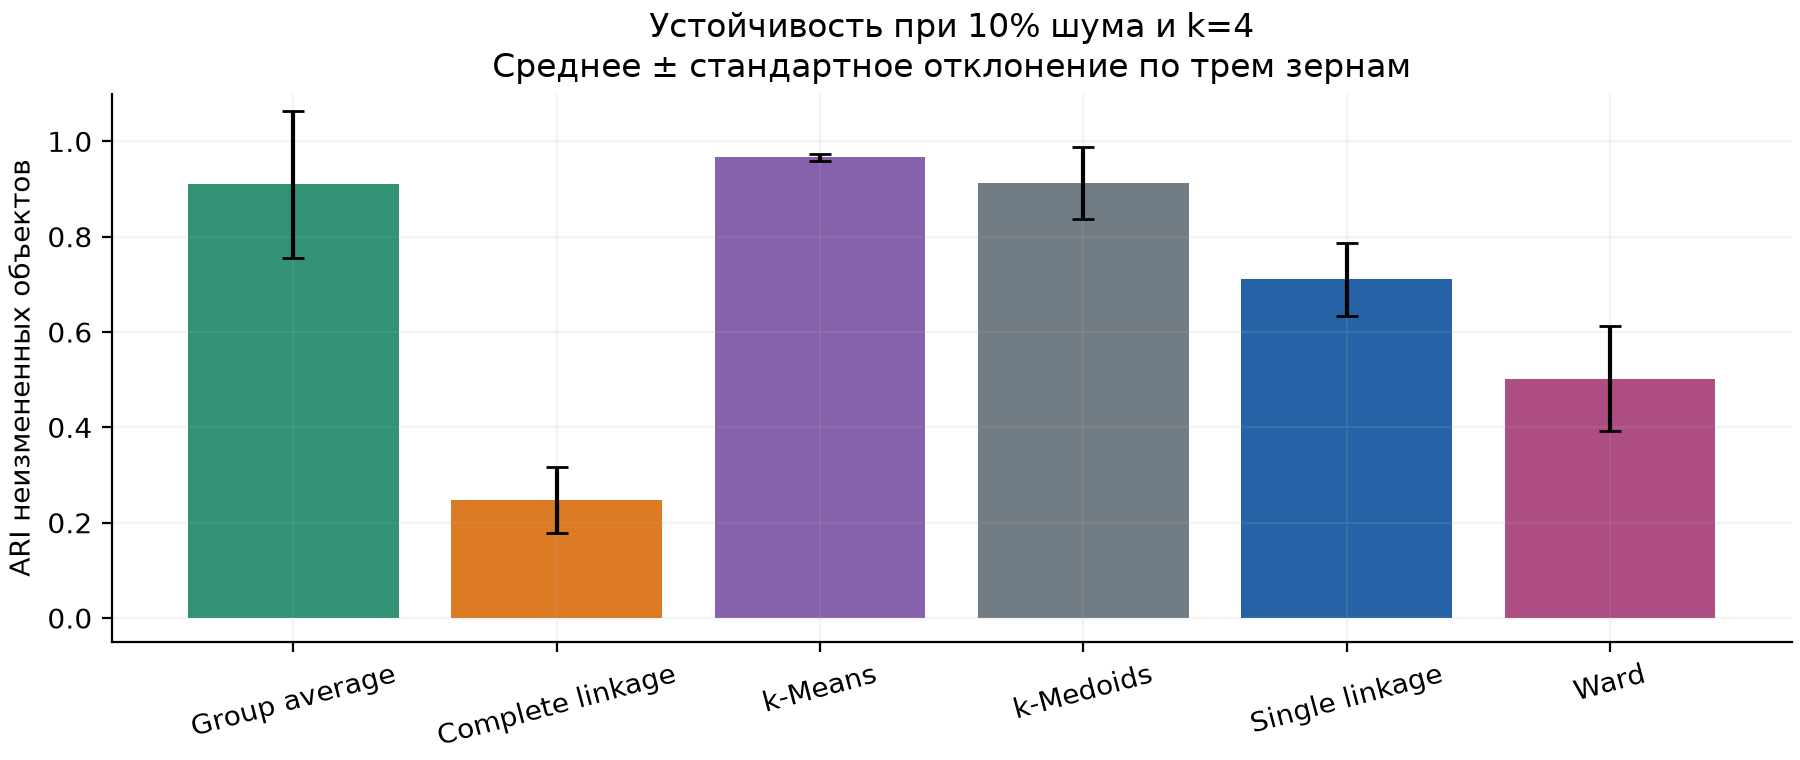

In [12]:
if "noise" in result:
    display(result["noise"].groupby("algorithm").ari_intact.agg(["mean","std"]).round(4))
    display(Image(filename=str(PROJECT/"results/figures/noise_stability.png")))
else:
    print("Дополнительный эксперимент отключен в параметрах.")


## 10 Независимые проверки и воспроизведение прежних алгоритмов

Проверяются формулы четырех мер прямым пересчетом межкластерных расстояний на
малых наборах, совпадение со SciPy, все возможные k, дубликаты, обработка ошибочных
параметров и равенство накопленной SSE Ward сумме h²/2. Основные четыре дерева
customers также сверяются со SciPy. При ничьих разные реализации могут выбрать
разные допустимые пары; в данном customers сравниваемые разрезы совпадают.

По умолчанию прежние результаты читаются из архива, чтобы сравнивать именно
прошлую работу. Флаг `RECOMPUTE_PARTITION_BASELINES=True` повторно выполнит
прежние реализации k-Means и PAM при k=K и сравнит с сохраненными результатами.


In [13]:
sys.path.insert(0, str((PROJECT/"src").resolve()))
from check_algorithms import main as check_algorithms
check_algorithms()
if RECOMPUTE_PARTITION_BASELINES:
    if not is_original or K not in range(3,10):
        raise ValueError("Проверка прежнего архива рассчитана на customers и k=3..9")
    from partition_reference import kmeans, pam
    from sklearn.metrics import adjusted_rand_score
    for repeat, seed in enumerate(SEEDS):
        for algorithm, fitter in [("kmeans", kmeans), ("kmedoids", pam)]:
            fit = fitter(X, K, seed=seed, n_init=5)
            archived = baseline_labels[f"{algorithm}_k{K}_p0.00_r{repeat}_labels"]
            assert adjusted_rand_score(fit.labels, archived) == 1
            print(algorithm, seed, "совпадение с прежним разбиением подтверждено")


OK: определения четырех мер; SciPy; все k; SSE Ward; дубликаты; валидация; медианы


## 11 Сохранение результатов

ZIP содержит исходный CSV, архив предыдущей работы, исходники, параметры
стандартизации, linkage-матрицы, все метки, метрики, графики и версии библиотек.
`all_points.csv` хранит исходные поля, использованные z-координаты и метки всех
28 разрезов. Локально программа одного запуска работает через `src/hierarchy.py`.

Материалы: М.Л. Цымблер, «04 Кластеризация», 23.04.2021, слайды 33–61, 64, 67;
описание customers из задания ЮУрГУ. Лекции «03 Классификация-2» и «02 Шаблоны»
относятся к другим задачам анализа данных и не задают целевые метки кластеризации.

Документация: [SciPy linkage](https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.linkage.html),
[Silhouette и ARI](https://scikit-learn.org/stable/modules/clustering.html#clustering-performance-evaluation).


In [14]:
archive = Path("Hierarchical_Customers_Results.zip")
with zipfile.ZipFile(archive,"w",compression=zipfile.ZIP_DEFLATED) as z:
    for path in sorted(PROJECT.rglob("*")):
        if path.is_file() and "__pycache__" not in path.parts:
            z.write(path,str(path.relative_to(PROJECT.parent)))
print("Результаты сохранены:",archive.name)
if DOWNLOAD_RESULTS:
    try:
        from google.colab import files
    except ImportError:
        print("Автоскачивание доступно в Colab; локально используйте указанный путь.")
    else:
        files.download(str(archive))


Результаты сохранены: Hierarchical_Customers_Results.zip
